# Ballon d'Or 2026 — EDA, preparation and modelling

Companion to `ballon_dor_2026_modelling_spec.md`. This notebook grows step by step.

## A. Load and describe
Goal of this step: load both snapshots and see what we have — shape, size, data types and how much data is there. No cleaning, no features, no modelling yet.

In [1]:
import hashlib
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 7
T1_PATH = Path("player_snapshot_t1.csv")
T2_PATH = Path("player_snapshot_t2.csv")
TARGET_COLS = ["bdo_points", "bdo_rank", "vote_share"]
FORECAST_EDITION = 2026

np.random.seed(SEED)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
print("git commit :", commit)
print("pandas     :", pd.__version__, "| numpy:", np.__version__)
for p in (T1_PATH, T2_PATH):
    print(f"{p.name:26s} sha256={sha256(p)[:16]}...")

git commit : 90dab5c
pandas     : 3.0.6 | numpy: 2.5.4
player_snapshot_t1.csv     sha256=249bb1ac9a623070...
player_snapshot_t2.csv     sha256=f9af1fd20747536e...


In [2]:
t1 = pd.read_csv(T1_PATH)
t2 = pd.read_csv(T2_PATH)
print("Loaded.")

Loaded.


### A1. Shape and size

In [3]:
size = pd.DataFrame({
    "rows": [len(t1), len(t2)],
    "columns": [t1.shape[1], t2.shape[1]],
    "cells": [t1.size, t2.size],
    "file_size_kb": [T1_PATH.stat().st_size / 1024, T2_PATH.stat().st_size / 1024],
    "memory_kb": [t1.memory_usage(deep=True).sum() / 1024, t2.memory_usage(deep=True).sum() / 1024],
}, index=["T1", "T2"]).round(1)
display(size)

extra = [c for c in t2.columns if c not in t1.columns]
missing_from_t2 = [c for c in t1.columns if c not in t2.columns]
print(f"T2 has {len(extra)} extra columns (post-window block); T1 columns missing from T2: {missing_from_t2}")
print(extra)

,rows,columns,cells,file_size_kb,memory_kb
T1,150,91,13650,102.3,186.9
T2,150,111,16650,130.3,208.3


T2 has 20 extra columns (post-window block); T1 columns missing from T2: []
['wiki_views_post', 'wiki_views_post_juror_w', 'wiki_views_final14', 'wiki_views_final14_juror_w', 'news_vol_post', 'news_vol_post_juror_w', 'news_coverage_ratio_post', 'news_tone_post', 'news_headlines_scored_post', 'post_minutes', 'post_apps', 'post_goal_contribs', 'post_npxg_xa_p90', 'post_npxg_xa_p90_opp_adj', 'post_avg_rating', 'post_big_game_rating', 'post_ucl_goal_contribs', 'post_intl_goal_contribs', 'post_transfer', 'post_injury']


### A2. Data types

In [4]:
def dtype_group(s: pd.Series) -> str:
    if pd.api.types.is_bool_dtype(s):
        return "bool"
    if pd.api.types.is_integer_dtype(s):
        return "integer"
    if pd.api.types.is_float_dtype(s):
        return "float"
    return "text/object"

counts = pd.DataFrame({
    "T1": t1.apply(dtype_group).value_counts(),
    "T2": t2.apply(dtype_group).value_counts(),
}).fillna(0).astype(int)
display(counts)

,T1,T2
bool,13,15
float,30,40
integer,34,42
text/object,14,14


In [5]:
BLOCKS = {
    "identity": ["edition", "snapshot", "snapshot_date", "player_key", "player_name", "nationality", "position_group",
                 "age_at_window_end", "is_goalkeeper", "club_key", "club_team_id", "league_key", "built_at", "pipeline_version"],
    "targets": TARGET_COLS,
    "history": ["prev_bdo_rank", "career_bdo_podiums_before", "is_defending_winner", "consecutive_podiums"],
    "club_performance": [c for c in t1.columns if c.startswith(("club_minutes", "club_apps", "club_goals", "club_assists",
                         "club_np", "club_xa", "club_xg", "club_avg", "big_game", "ucl_minutes", "ucl_goal", "ucl_ko"))],
    "international": [c for c in t1.columns if c.startswith(("intl_", "tourn_", "finals_", "final_", "scored_winner"))],
    "honors": ["won_ucl", "won_league", "won_domestic_cup", "won_world_cup", "won_continental", "won_other_uefa",
               "ucl_back_to_back", "league_poty", "club_trophies_n"],
    "team_context": ["league_finish", "league_n_teams", "league_finish_partial", "ucl_stage_reached", "club_rating_window_end",
                     "club_rating_rank_window_end", "club_rating_fallback", "uefa_country_coeff_rank", "league_mean_rating",
                     "nt_fifa_rank_window_end", "nt_elo_window_end", "nt_tourn_stage_reached"],
    "attention": [c for c in t1.columns if c.startswith(("wiki_", "news_"))],
    "voter_context": ["jurors_same_nation", "jurors_same_confed", "jurors_league_country", "teammates_on_shortlist",
                      "nat_teammates_on_shortlist"],
    "post_window_T2_only": extra,
}
assigned = [c for cols in BLOCKS.values() for c in cols]
unassigned = [c for c in t2.columns if c not in assigned]
dupes = pd.Series(assigned).loc[lambda s: s.duplicated()].tolist()
print("unassigned columns:", unassigned)
print("columns in more than one block:", dupes)

unassigned columns: []
columns in more than one block: []


In [6]:
block_of = {c: b for b, cols in BLOCKS.items() for c in cols[::-1]}
profile = pd.DataFrame({
    "block": pd.Series(block_of),
    "dtype": t2.dtypes.astype(str),
    "non_null": t2.notna().sum(),
    "null": t2.isna().sum(),
    "null_%": (t2.isna().mean() * 100).round(1),
    "n_unique": t2.nunique(),
}).loc[t2.columns]
profile.insert(0, "in_T1", [c in t1.columns for c in profile.index])
display(profile)

,in_T1,block,dtype,non_null,null,null_%,n_unique
edition,True,identity,int64,150,0,0.0,5
snapshot,True,identity,str,150,0,0.0,1
snapshot_date,True,identity,str,150,0,0.0,5
player_key,True,identity,str,150,0,0.0,91
player_name,True,identity,str,150,0,0.0,91
nationality,True,identity,str,150,0,0.0,33
position_group,True,identity,str,150,0,0.0,4
age_at_window_end,True,identity,float64,150,0,0.0,97
is_goalkeeper,True,identity,bool,150,0,0.0,2
bdo_points,True,targets,float64,120,30,20.0,71


### A3. How much data is there?

In [7]:
per_edition = pd.concat({"T1": t1, "T2": t2}).reset_index(level=0).rename(columns={"level_0": "table"})
rows = per_edition.groupby(["edition", "table"]).size().unstack()
rows["role"] = np.where(rows.index == FORECAST_EDITION, "forecast (targets null)", "train / back-test")
display(rows)

uniq = pd.Series({
    "player-season rows": len(t1),
    "distinct players": t1["player_key"].nunique(),
    "distinct clubs": t1["club_key"].nunique(),
    "distinct nationalities": t1["nationality"].nunique(),
    "distinct leagues": t1["league_key"].nunique(),
})
display(uniq.to_frame("count"))

appearances = t1.groupby("player_key").size()
print("Nominations per player (how many players appear in 1, 2, ... 5 editions):")
display(appearances.value_counts().sort_index().rename_axis("editions_nominated").to_frame("players"))

table,T1,T2,role
edition,,,
2022,30,30,train / back-test
2023,30,30,train / back-test
2024,30,30,train / back-test
2025,30,30,train / back-test
2026,30,30,forecast (targets null)


,count
player-season rows,150
distinct players,91
distinct clubs,31
distinct nationalities,33
distinct leagues,9


Nominations per player (how many players appear in 1, 2, ... 5 editions):


,players
editions_nominated,
1,55
2,23
3,7
4,2
5,4


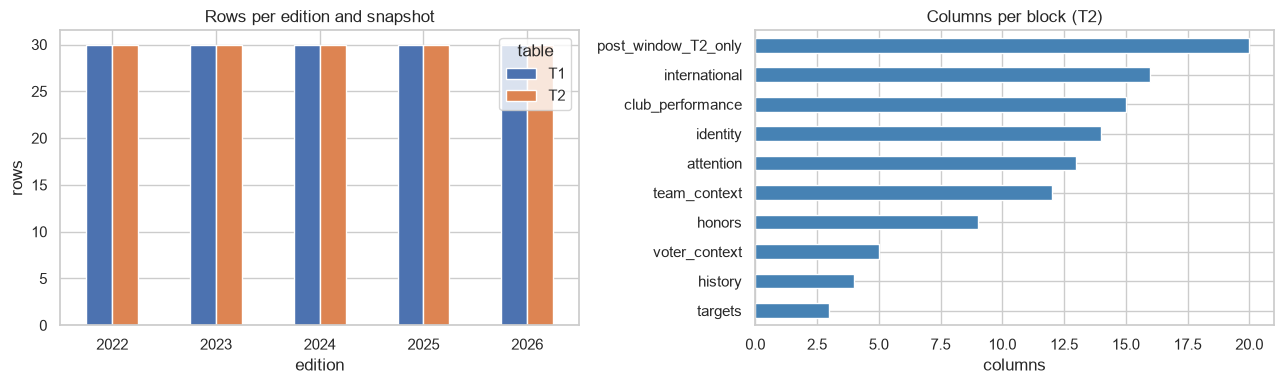

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rows[["T1", "T2"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Rows per edition and snapshot")
axes[0].set_ylabel("rows")
block_sizes = pd.Series({b: len([c for c in cols if c in t2.columns]) for b, cols in BLOCKS.items()}).sort_values()
block_sizes.plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("Columns per block (T2)")
axes[1].set_xlabel("columns")
plt.tight_layout()
Path("figures/eda").mkdir(parents=True, exist_ok=True)
plt.savefig("figures/eda/a_size_overview.png", dpi=150)
plt.show()

### A4. First look

In [9]:
display(t1.head(8).T.head(45))

,0,1,2,3,4,5,6,7
edition,2022,2022,2022,2022,2022,2022,2022,2022
snapshot,T1,T1,T1,T1,T1,T1,T1,T1
snapshot_date,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31,2022-07-31
player_key,p_q11571,p_q133903,p_q1354960,p_q13865408,p_q151269,p_q15521306,p_q17274709,p_q1912
player_name,Cristiano Ronaldo,Virgil van Dijk,Mohamed Salah,Joshua Kimmich,Robert Lewandowski,Bernardo Silva,Mike Maignan,Karim Benzema
nationality,Portugal,Netherlands,Egypt,Germany,Poland,Portugal,France,France
position_group,FWD,DEF,FWD,MID,FWD,MID,GK,FWD
age_at_window_end,37.5,31.1,30.1,27.5,33.9,28.0,27.1,34.6
is_goalkeeper,False,False,False,False,False,False,True,False
bdo_points,0.0,1.0,116.0,0.0,170.0,0.0,0.0,549.0


In [10]:
cats = ["position_group", "ucl_stage_reached", "nt_tourn_stage_reached", "tourn_individual_award", "tourn_name", "league_key"]
for c in cats:
    print(f"--- {c}")
    print(t1[c].value_counts(dropna=False).to_string())
    print()

--- position_group
position_group
FWD    70
MID    47
DEF    26
GK      7

--- ucl_stage_reached
ucl_stage_reached
winner          35
QF              29
R16             21
SF              21
NaN             19
final           15
league_phase     7
playoff          3

--- nt_tourn_stage_reached
nt_tourn_stage_reached
NaN       67
winner    18
QF        15
SF        15
R16       14
final     12
group      7
R32        2

--- tourn_individual_award
tourn_individual_award
NaN                            128
Player of the Tournament        11
Best young player                6
Golden Boot winner (Europe)      5

--- tourn_name
tourn_name
NaN                      67
World Cup                52
EURO                     22
Africa Cup of Nations     5
Copa America              4

--- league_key
league_key
47     49
87     33
53     23
54     22
55     16
61      3
536     2
57      1
130     1



In [11]:
key_numeric = ["age_at_window_end", "club_minutes", "club_npxg_xa_p90_opp_adj", "club_avg_rating", "intl_minutes",
               "club_rating_window_end", "wiki_views_in", "news_vol_in", "bdo_points", "vote_share"]
display(t1[key_numeric].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age_at_window_end,150.0,27.30,4.41,17.10,24.10,27.00,30.18,39.10
club_minutes,150.0,3700.02,634.89,1713.00,3243.50,3805.50,4152.75,5015.00
club_npxg_xa_p90_opp_adj,150.0,0.43,0.28,-0.13,0.20,0.45,0.65,1.08
club_avg_rating,150.0,7.63,0.33,6.52,7.45,7.64,7.85,8.45
intl_minutes,150.0,639.80,283.70,0.00,452.25,625.00,817.00,1440.00
club_rating_window_end,148.0,1948.09,101.76,1639.00,1886.00,1963.50,2026.00,2111.00
wiki_views_in,150.0,6179451.23,8449058.89,960376.00,2297207.25,3529510.50,6296706.50,67307175.00
news_vol_in,150.0,10930.54,11715.03,1167.39,3548.18,7184.54,14120.90,79168.22
bdo_points,120.0,135.78,262.15,0.00,3.75,20.00,117.75,1380.00
vote_share,120.0,0.03,0.06,0.00,0.00,0.01,0.03,0.37


### A5. Quick sanity checks (printed only, nothing is modified)

In [12]:
print("(edition, player_key) unique in T1:", not t1.duplicated(["edition", "player_key"]).any())
print("(edition, player_key) unique in T2:", not t2.duplicated(["edition", "player_key"]).any())
shared = t1.columns
print("T1 in-window columns identical in T2:",
      t1.reset_index(drop=True).equals(t2[shared].reset_index(drop=True)) or
      t1.sort_values(["edition", "player_key"]).reset_index(drop=True).drop(columns=["snapshot", "snapshot_date"]).equals(
          t2.sort_values(["edition", "player_key"]).reset_index(drop=True)[shared].drop(columns=["snapshot", "snapshot_date"])))
print("2026 target columns entirely null:", bool(t1.loc[t1.edition == FORECAST_EDITION, TARGET_COLS].isna().all().all()))
print("2022-25 target columns have no nulls:", bool(t1.loc[t1.edition < FORECAST_EDITION, TARGET_COLS].notna().all().all()))

(edition, player_key) unique in T1: True
(edition, player_key) unique in T2: True
T1 in-window columns identical in T2: True
2026 target columns entirely null: True
2022-25 target columns have no nulls: True


## B. Spec section 2 — edition facts, data quirks and missingness

Everything here is checked against the claims in section 2 of the modelling spec. Checks are printed as `observed` vs `spec` so any mismatch is visible; nothing is modified.

### B1. Edition facts (window end, post-window days, ballot scheme, point totals)

In [13]:
EDITION_FACTS = pd.DataFrame({
    "window_end": pd.to_datetime(["2022-07-31", "2023-07-31", "2024-07-31", "2025-07-13", "2026-07-19"]),
    "spec_t2_date": pd.to_datetime(["2022-09-16", "2023-09-29", "2024-09-27", "2025-08-22", "2026-09-25"]),
    "spec_post_days": [47, 60, 58, 40, 68],
    "ballot_size": [5, 5, 10, 10, 10],
    "points_per_ballot": [16, 16, 67, 67, 67],
    "jurors": [93, 92, 99, 100, 100],
}, index=pd.Index([2022, 2023, 2024, 2025, 2026], name="edition"))

obs = t2.groupby("edition").agg(snapshot_date=("snapshot_date", "first"), n_snapshot_dates=("snapshot_date", "nunique"))
obs["snapshot_date"] = pd.to_datetime(obs["snapshot_date"])
facts = EDITION_FACTS.join(obs)
facts["observed_post_days"] = (facts["snapshot_date"] - facts["window_end"]).dt.days
facts["t2_date_matches"] = facts["snapshot_date"] == facts["spec_t2_date"]
facts["post_days_match"] = facts["observed_post_days"] == facts["spec_post_days"]
facts["observed_points_total"] = t1.groupby("edition")["bdo_points"].sum()
facts["expected_points_total"] = facts["jurors"] * facts["points_per_ballot"]
facts["points_match"] = facts["observed_points_total"] == facts["expected_points_total"]
display(facts[["window_end", "snapshot_date", "observed_post_days", "spec_post_days", "t2_date_matches", "post_days_match",
               "ballot_size", "jurors", "observed_points_total", "expected_points_total", "points_match"]])

t1_dates = t1.groupby("edition")["snapshot_date"].agg(["first", "nunique"])
print("T1 snapshot dates (should equal window end):")
display(t1_dates)

,window_end,snapshot_date,observed_post_days,spec_post_days,t2_date_matches,post_days_match,ballot_size,jurors,observed_points_total,expected_points_total,points_match
edition,,,,,,,,,,,
2022,2022-07-31,2022-09-16,47,47,True,True,5,93,1488.0,1488,True
2023,2023-07-31,2023-09-29,60,60,True,True,5,92,1472.0,1472,True
2024,2024-07-31,2024-09-27,58,58,True,True,10,99,6633.0,6633,True
2025,2025-07-13,2025-08-22,40,40,True,True,10,100,6700.0,6700,True
2026,2026-07-19,2026-09-25,68,68,True,True,10,100,0.0,6700,False


T1 snapshot dates (should equal window end):


,first,nunique
edition,,
2022,2022-07-31,1
2023,2023-07-31,1
2024,2024-07-31,1
2025,2025-07-13,1
2026,2026-07-19,1


### B2. Known data quirks — spec claim vs what the data shows

In [14]:
train = t1[t1["edition"] < FORECAST_EDITION]
intl_null = t1["intl_npxg_xa_p90"].isna()
neg_adj = t1["club_npxg_xa_p90_opp_adj"] < 0
voted = train[train["bdo_points"] > 0]
tied_voted = voted.groupby(["edition", "bdo_points"]).filter(lambda g: len(g) > 1)
rating_null = t1[t1["club_rating_window_end"].isna()]

quirks = pd.DataFrame([
    ("Zero-point nominees, 2022-24", 18, int((train.query("edition <= 2024")["bdo_points"] == 0).sum())),
    ("Zero-point nominees, 2025", 0, int((train.query("edition == 2025")["bdo_points"] == 0).sum())),
    ("intl_npxg_xa_p90 null rows", 18, int(intl_null.sum())),
    ("  ...of which intl_minutes < 270", 18, int((intl_null & (t1["intl_minutes"] < 270)).sum())),
    ("  ...rows with intl_minutes < 270 but NOT null", None, int((~intl_null & (t1["intl_minutes"] < 270)).sum())),
    ("intl_npxg_xa_p90_opp_adj null rows", 18, int(t1["intl_npxg_xa_p90_opp_adj"].isna().sum())),
    ("club_rating_window_end null rows", 2, int(len(rating_null))),
    ("big_game_rating null rows", 3, int(t1["big_game_rating"].isna().sum())),
    ("Negative club_npxg_xa_p90_opp_adj rows", 10, int(neg_adj.sum())),
    ("  ...of which GK or DEF", 10, int(t1.loc[neg_adj, "position_group"].isin(["GK", "DEF"]).sum())),
    ("Goalkeepers in 2026", 0, int(t1.query("edition == 2026")["is_goalkeeper"].sum())),
    ("Goalkeepers per edition max", 3, int(t1.groupby("edition")["is_goalkeeper"].sum().max())),
    ("YouTube columns present", 0, int(sum("youtube" in c.lower() for c in t2.columns))),
    ("2025: post_npxg_xa_p90 null rows (of 30)", 29, int(t2.query("edition == 2025")["post_npxg_xa_p90"].isna().sum())),
    ("2025: median post_apps", 1, float(t2.query("edition == 2025")["post_apps"].median())),
], columns=["quirk", "spec_says", "observed"])
quirks["match"] = quirks.apply(lambda r: "n/a" if r["spec_says"] is None or pd.isna(r["spec_says"]) else r["spec_says"] == r["observed"], axis=1)
display(quirks)

print("club_rating_window_end null rows:")
display(rating_null[["edition", "player_name", "club_key", "league_key"]])
print("intl_xg_missing flag by edition:")
display(t1.groupby("edition")["intl_xg_missing"].agg(["sum", "count"]))
print("Rows with big_game_rating null:")
display(t1.loc[t1["big_game_rating"].isna(), ["edition", "player_name", "club_avg_rating", "club_minutes"]])

,quirk,spec_says,observed,match
0,"Zero-point nominees, 2022-24",18.0,18.0,True
1,"Zero-point nominees, 2025",0.0,0.0,True
2,intl_npxg_xa_p90 null rows,18.0,18.0,True
3,...of which intl_minutes < 270,18.0,18.0,True
4,...rows with intl_minutes < 270 but NOT null,NaN,0.0,n/a
5,intl_npxg_xa_p90_opp_adj null rows,18.0,18.0,True
6,club_rating_window_end null rows,2.0,2.0,True
7,big_game_rating null rows,3.0,3.0,True
8,Negative club_npxg_xa_p90_opp_adj rows,10.0,10.0,True
9,...of which GK or DEF,10.0,10.0,True


club_rating_window_end null rows:


,edition,player_name,club_key,league_key
131,2026,Julián Quiñones,c_al_qadsiah,536
142,2026,Lionel Messi,c_inter_miami_cf,130


intl_xg_missing flag by edition:


,sum,count
edition,,
2022,9,30
2023,0,30
2024,0,30
2025,6,30
2026,0,30


Rows with big_game_rating null:


,edition,player_name,club_avg_rating,club_minutes
127,2026,Sadio Mané,7.832758,2712
131,2026,Julián Quiñones,7.930805,3042
142,2026,Lionel Messi,8.453526,2998


In [15]:
# Null stage columns should mean "did not play in the competition"
ucl_null = t1["ucl_stage_reached"].isna()
nt_null = t1["nt_tourn_stage_reached"].isna()
print("ucl_stage_reached null rows:", int(ucl_null.sum()), "| of which ucl_minutes == 0:", int((ucl_null & (t1["ucl_minutes"] == 0)).sum()),
      "| ucl_minutes == 0 but stage present:", int((~ucl_null & (t1["ucl_minutes"] == 0)).sum()))
print("nt_tourn_stage_reached null rows:", int(nt_null.sum()), "| of which tourn_minutes null or 0:",
      int((nt_null & (t1["tourn_minutes"].fillna(0) == 0)).sum()),
      "| tourn_minutes > 0 but stage null:", int((nt_null & (t1["tourn_minutes"].fillna(0) > 0)).sum()))
print()
print("Tournament played, per edition (non-null nt_tourn_stage_reached):")
display(t1.groupby("edition").agg(tournament=("tourn_name", lambda s: s.dropna().unique().tolist()),
                                  players_in_tournament=("nt_tourn_stage_reached", "count")))

ucl_stage_reached null rows: 19 | of which ucl_minutes == 0: 19 | ucl_minutes == 0 but stage present: 0
nt_tourn_stage_reached null rows: 67 | of which tourn_minutes null or 0: 67 | tourn_minutes > 0 but stage null: 0

Tournament played, per edition (non-null nt_tourn_stage_reached):


,tournament,players_in_tournament
edition,,
2022,[Africa Cup of Nations],4
2023,[World Cup],23
2024,"[EURO, Copa America, Africa Cup of Nations]",27
2025,[],0
2026,[World Cup],29


### B3. Missingness map

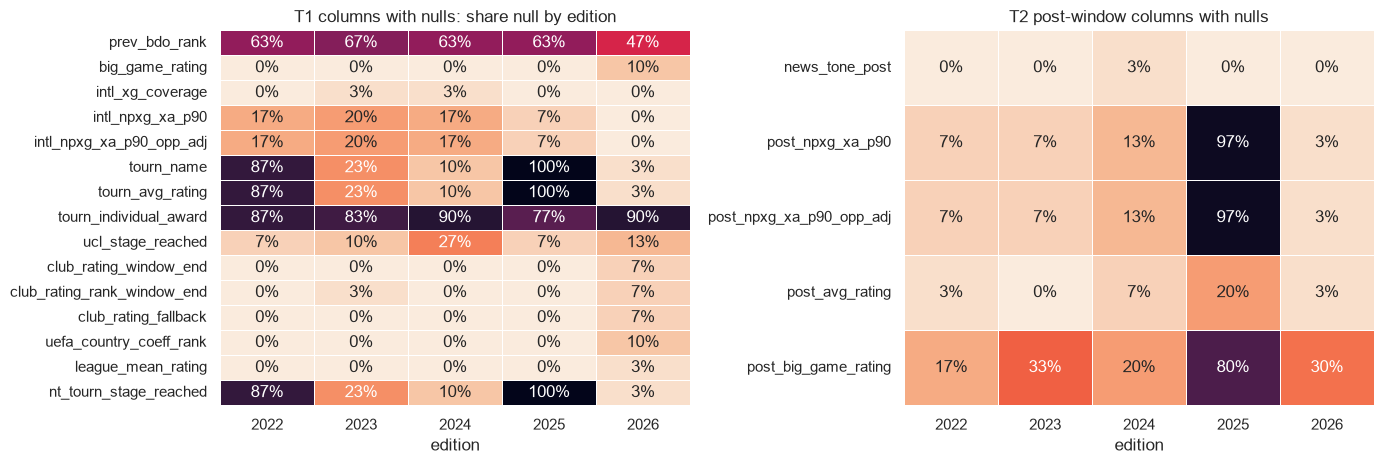

Targets (bdo_points / bdo_rank / vote_share) are null for 2026 only: the forecast edition.


In [16]:
def null_share_by_edition(df: pd.DataFrame) -> pd.DataFrame:
    shares = df.drop(columns=["edition"]).isna().groupby(df["edition"]).mean().T
    return shares.loc[shares.sum(axis=1) > 0]

miss_t1 = null_share_by_edition(t1.drop(columns=TARGET_COLS))
miss_post = null_share_by_edition(t2[["edition"] + extra])

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.32 * max(len(miss_t1), len(miss_post)))), gridspec_kw={"width_ratios": [1, 1]})
sns.heatmap(miss_t1, annot=True, fmt=".0%", cmap="rocket_r", vmin=0, vmax=1, cbar=False, ax=axes[0], linewidths=0.5)
axes[0].set_title("T1 columns with nulls: share null by edition")
sns.heatmap(miss_post, annot=True, fmt=".0%", cmap="rocket_r", vmin=0, vmax=1, cbar=False, ax=axes[1], linewidths=0.5)
axes[1].set_title("T2 post-window columns with nulls")
for ax in axes:
    ax.set_xlabel("edition")
plt.tight_layout()
plt.savefig("figures/eda/b_missingness_by_edition.png", dpi=150)
plt.show()
print("Targets (bdo_points / bdo_rank / vote_share) are null for 2026 only: the forecast edition.")

In [17]:
# Which nulls are 'structural' (did not play) vs 'unexplained'? Totals per column, all editions.
tot = t2.isna().sum()
tot = tot[tot > 0].sort_values(ascending=False).to_frame("null_rows")
tot["null_%"] = (tot["null_rows"] / len(t2) * 100).round(1)
display(tot)

,null_rows,null_%
tourn_individual_award,128,85.3
prev_bdo_rank,91,60.7
tourn_avg_rating,67,44.7
nt_tourn_stage_reached,67,44.7
tourn_name,67,44.7
post_big_game_rating,54,36.0
post_npxg_xa_p90_opp_adj,38,25.3
post_npxg_xa_p90,38,25.3
bdo_rank,30,20.0
bdo_points,30,20.0


### B4. Target anatomy — how the points are distributed

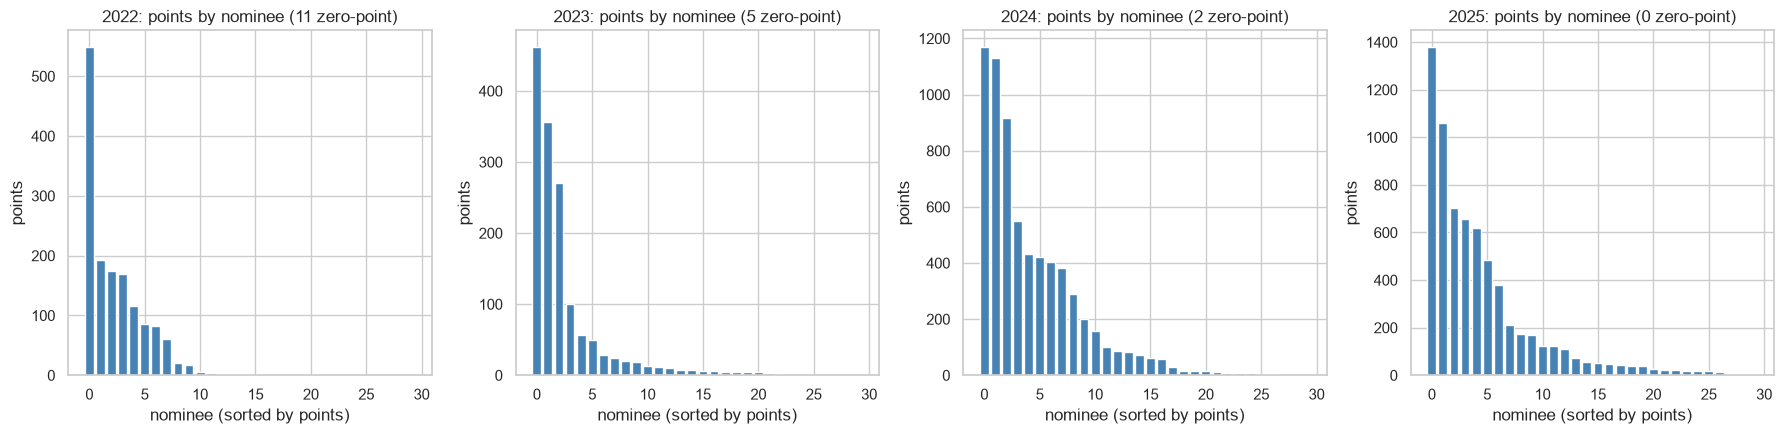

,points_total,n_voted,n_zero_points,winner_points,winner_share,top3_share,herfindahl,winner
edition,,,,,,,,
2022,1488.0,19,11,549.0,0.368952,0.616263,0.194243,Karim Benzema
2023,1472.0,25,5,462.0,0.313859,0.739810,0.199489,Lionel Messi
2024,6633.0,28,2,1170.0,0.176391,0.484848,0.105609,Rodri
2025,6700.0,30,0,1380.0,0.205970,0.468955,0.108736,Ousmane Dembélé


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=False)
for ax, (ed, g) in zip(axes, train.groupby("edition")):
    g = g.sort_values(["bdo_points", "player_name"], ascending=[False, True]).reset_index(drop=True)
    colors = np.where(g["bdo_points"] == 0, "lightgrey", "steelblue")
    ax.bar(range(len(g)), g["bdo_points"], color=colors)
    ax.set_title(f"{ed}: points by nominee ({(g['bdo_points'] == 0).sum()} zero-point)")
    ax.set_xlabel("nominee (sorted by points)")
    ax.set_ylabel("points")
plt.tight_layout()
plt.savefig("figures/eda/b_points_by_edition.png", dpi=150)
plt.show()

conc = train.groupby("edition").apply(lambda g: pd.Series({
    "points_total": g["bdo_points"].sum(),
    "n_voted": int((g["bdo_points"] > 0).sum()),
    "n_zero_points": int((g["bdo_points"] == 0).sum()),
    "winner_points": g["bdo_points"].max(),
    "winner_share": g["bdo_points"].max() / g["bdo_points"].sum(),
    "top3_share": g["bdo_points"].nlargest(3).sum() / g["bdo_points"].sum(),
    "herfindahl": ((g["bdo_points"] / g["bdo_points"].sum()) ** 2).sum(),
    "winner": g.loc[g["bdo_points"].idxmax(), "player_name"],
}), include_groups=False)
display(conc)

In [19]:
# vote_share consistency and rank vs points
share_gap = (train["vote_share"] - train["bdo_points"] / train.groupby("edition")["bdo_points"].transform("sum")).abs().max()
print(f"max |vote_share - points/total| = {share_gap:.2e}")

print("Tied point totals among VOTED players (these need Breslow handling later):")
display(tied_voted.sort_values(["edition", "bdo_points"], ascending=[True, False])[["edition", "player_name", "bdo_points", "bdo_rank"]])

print("Zero-point nominees and their bdo_rank (rank is shared/tied -> points, not rank, must define the order):")
display(train[train["bdo_points"] == 0].groupby("edition")["bdo_rank"].apply(lambda s: sorted(s.tolist())).to_frame("zero_point_ranks"))
print("bdo_rank unique per edition:", train.groupby("edition")["bdo_rank"].apply(lambda s: s.is_unique).to_dict())

max |vote_share - points/total| = 9.63e-17
Tied point totals among VOTED players (these need Breslow handling later):


,edition,player_name,bdo_points,bdo_rank
16,2022,Rafael Leão,2.0,14.0
24,2022,Fabinho,2.0,14.0
26,2022,Sébastien Haller,2.0,13.0
1,2022,Virgil van Dijk,1.0,16.0
11,2022,Dušan Vlahović,1.0,17.0
13,2022,Luis Díaz,1.0,17.0
22,2022,Casemiro,1.0,17.0
36,2023,Karim Benzema,6.0,16.0
55,2023,Khvicha Kvaratskhelia,6.0,17.0
39,2023,Lautaro Martínez,4.0,20.0


Zero-point nominees and their bdo_rank (rank is shared/tied -> points, not rank, must define the order):


,zero_point_ranks
edition,
2022,"[20.0, 21.0, 22.0, 22.0, 22.0, 25.0, 25.0, 25...."
2023,"[26.0, 27.0, 28.0, 28.0, 30.0]"
2024,"[29.0, 29.0]"


bdo_rank unique per edition: {2022: False, 2023: False, 2024: False, 2025: True}


### B5. Who the nominees are — positions and the 2026 forecast pool

position_group,DEF,FWD,GK,MID
edition,,,,
2022,4,15,2,9
2023,3,15,3,9
2024,6,11,1,12
2025,4,15,1,10
2026,9,14,0,7


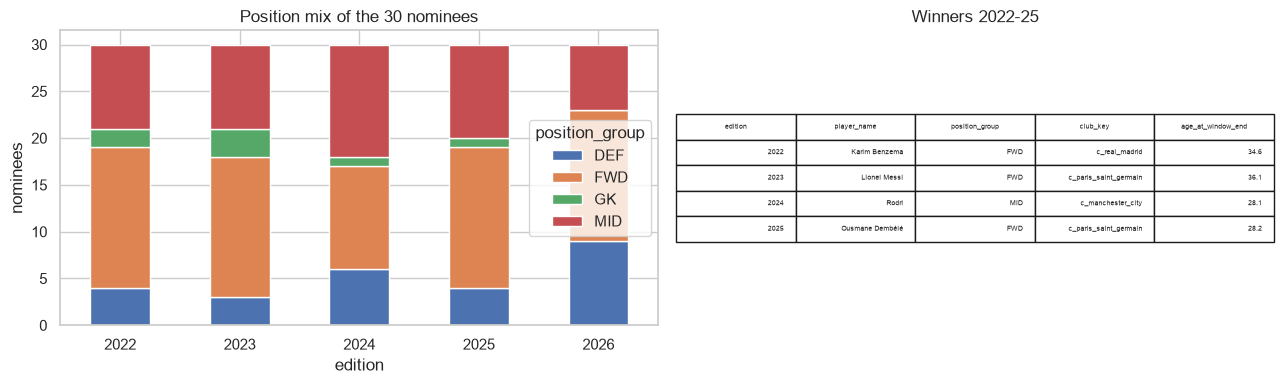

In [20]:
pos = pd.crosstab(t1["edition"], t1["position_group"])
display(pos)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pos.plot.bar(stacked=True, ax=ax[0], rot=0)
ax[0].set_title("Position mix of the 30 nominees")
ax[0].set_ylabel("nominees")
winners = train.loc[train.groupby("edition")["bdo_points"].idxmax(), ["edition", "player_name", "position_group", "club_key", "age_at_window_end"]]
ax[1].axis("off")
ax[1].table(cellText=winners.values, colLabels=winners.columns, loc="center").scale(1, 1.6)
ax[1].set_title("Winners 2022-25")
plt.tight_layout()
plt.savefig("figures/eda/b_positions_and_winners.png", dpi=150)
plt.show()

## C. Feature-level EDA — which raw inputs move the outcome?

**Descriptive only.** The 10-feature set in spec section 3.1 is pre-registered, so nothing in this section may be used to drop, add or re-weight features. The goal is to understand the data: how each candidate input is distributed, how it relates to Ballon d'Or points *within* an edition (voting is relative), and how much the inputs overlap.

Conventions used here (EDA only, these are not the final engineered features):
- Only the 120 labelled rows (editions 2022–25) are used for anything involving the outcome. 2026 is plotted for comparison only.
- Count-type nulls from not playing in a competition are filled with 0; ordinal stage nulls = 0; `prev_bdo_rank` null -> `prev_standing` 0.
- Heavy-tailed attention counts are `log1p`-transformed.
- 'Within-edition z' = subtract that edition's mean and divide by its sample SD (ddof=1); zero-SD columns become 0.

In [21]:
from scipy import stats

STAGE_ORDINAL = {"group": 1, "league_phase": 1, "R32": 2, "playoff": 2, "R16": 3, "QF": 4, "SF": 5, "final": 6, "winner": 7}
print("stage values present:", sorted(set(t1["ucl_stage_reached"].dropna()) | set(t1["nt_tourn_stage_reached"].dropna())))
print("NOTE: spec section 3.1 ordinals do not list 'playoff' (3 rows: Haaland 2025, Gyokeres 2025, Martinez 2026). It is the UCL knockout play-off, the same round as R32, so EDA maps it to 2. To be logged in deviations.md at the prep step.")

stage values present: ['QF', 'R16', 'R32', 'SF', 'final', 'group', 'league_phase', 'playoff', 'winner']
NOTE: spec section 3.1 ordinals do not list 'playoff' (3 rows: Haaland 2025, Gyokeres 2025, Martinez 2026). It is the UCL knockout play-off, the same round as R32, so EDA maps it to 2. To be logged in deviations.md at the prep step.


In [22]:
def build_raw_candidates(df: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index)
    out["edition"] = df["edition"]
    out["player_name"] = df["player_name"]
    out["position_group"] = df["position_group"]
    out["points"] = df["bdo_points"]
    # performance
    out["club_attack_p90"] = df["club_npxg_xa_p90_opp_adj"]
    out["intl_attack_p90"] = df["intl_npxg_xa_p90_opp_adj"]
    out["club_avg_rating"] = df["club_avg_rating"]
    out["big_game_rating"] = df["big_game_rating"].fillna(df["club_avg_rating"])
    out["club_goals"] = df["club_goals"]
    out["club_assists"] = df["club_assists"]
    out["club_minutes"] = df["club_minutes"]
    # big stage
    out["ucl_goal_contribs"] = df["ucl_goal_contribs"]
    out["ucl_ko_goal_contribs"] = df["ucl_ko_goal_contribs"]
    out["tourn_ko_goal_contribs"] = df["tourn_ko_goal_contribs"].fillna(0)
    out["final_goal_contribs"] = df["final_goal_contribs"].fillna(0)
    out["scored_winner_in_final"] = df["scored_winner_in_final"].fillna(False).astype(int)
    out["tourn_award"] = df["tourn_individual_award"].notna().astype(int)
    # honors
    out["major_titles"] = df[["won_ucl", "won_world_cup", "won_continental"]].astype(int).sum(axis=1)
    out["other_honors"] = df[["won_league", "won_domestic_cup", "won_other_uefa", "league_poty", "ucl_back_to_back"]].astype(int).sum(axis=1)
    out["won_ucl"] = df["won_ucl"].astype(int)
    out["won_world_cup"] = df["won_world_cup"].astype(int)
    # team strength
    out["club_rating"] = df["club_rating_window_end"]
    out["ucl_stage_ord"] = df["ucl_stage_reached"].map(STAGE_ORDINAL).fillna(0)
    out["nt_stage_ord"] = df["nt_tourn_stage_reached"].map(STAGE_ORDINAL).fillna(0)
    out["nt_elo"] = df["nt_elo_window_end"]
    # history
    out["prior_standing"] = (31 - df["prev_bdo_rank"]).fillna(0)
    out["defending_winner"] = df["is_defending_winner"].astype(int)
    out["career_podiums_before"] = df["career_bdo_podiums_before"]
    out["first_time"] = (df["career_bdo_podiums_before"] == 0).astype(int)
    out["age"] = df["age_at_window_end"]
    # attention
    out["log_wiki_pre"] = np.log1p(df["wiki_views_pre_juror_w"])
    out["log_wiki_in"] = np.log1p(df["wiki_views_in_juror_w"])
    out["wiki_change"] = out["log_wiki_in"] - out["log_wiki_pre"]
    out["log_news_pre"] = np.log1p(df["news_vol_pre_juror_w"])
    out["log_news_in"] = np.log1p(df["news_vol_in_juror_w"])
    out["news_change"] = out["log_news_in"] - out["log_news_pre"]
    out["news_tone"] = df["news_tone_in"]
    # voter context
    out["teammates_on_shortlist"] = df["teammates_on_shortlist"]
    out["jurors_same_confed"] = df["jurors_same_confed"]
    out["is_defender"] = (df["position_group"] == "DEF").astype(int)
    return out

raw = build_raw_candidates(t1)
ID_COLS = ["edition", "player_name", "position_group", "points"]
FEATURES = [c for c in raw.columns if c not in ID_COLS]
GROUPS = {
    "performance": ["club_attack_p90", "intl_attack_p90", "club_avg_rating", "big_game_rating", "club_goals", "club_assists", "club_minutes"],
    "big stage": ["ucl_goal_contribs", "ucl_ko_goal_contribs", "tourn_ko_goal_contribs", "final_goal_contribs", "scored_winner_in_final", "tourn_award"],
    "honors": ["major_titles", "other_honors", "won_ucl", "won_world_cup"],
    "team strength": ["club_rating", "ucl_stage_ord", "nt_stage_ord", "nt_elo"],
    "history": ["prior_standing", "defending_winner", "career_podiums_before", "first_time", "age"],
    "attention": ["log_wiki_pre", "log_wiki_in", "wiki_change", "log_news_pre", "log_news_in", "news_change", "news_tone"],
    "voter context / position": ["teammates_on_shortlist", "jurors_same_confed", "is_defender"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)
GROUP_OF = {f: g for g, fs in GROUPS.items() for f in fs}
print(f"{len(FEATURES)} candidate raw features in {len(GROUPS)} groups; remaining nulls per feature (all rows):")
nulls = raw[FEATURES].isna().sum()
display(nulls[nulls > 0].to_frame("null_rows"))
lab = raw[raw["edition"] < FORECAST_EDITION].copy()
print("labelled rows:", len(lab))

36 candidate raw features in 7 groups; remaining nulls per feature (all rows):


,null_rows
intl_attack_p90,18
club_rating,2


labelled rows: 120


### C1. Distributions of the candidate features

In [23]:
skew = lab[FEATURES].apply(lambda s: stats.skew(s.dropna())).rename("skew")
summary = lab[FEATURES].describe().T[["count", "mean", "std", "min", "50%", "max"]].join(skew).join(pd.Series(GROUP_OF, name="group"))
display(summary.sort_values(["group", "skew"], ascending=[True, False]).round(2))

,count,mean,std,min,50%,max,skew,group
log_news_in,120.0,1.07,0.69,0.34,0.89,4.95,2.52,attention
log_wiki_in,120.0,0.89,0.58,0.14,0.75,3.28,1.66,attention
log_news_pre,120.0,1.11,0.80,0.03,0.91,4.72,1.64,attention
log_wiki_pre,120.0,0.98,0.77,0.04,0.76,3.84,1.34,attention
wiki_change,120.0,-0.09,0.43,-1.30,-0.08,1.84,0.29,attention
news_change,120.0,-0.03,0.34,-1.03,-0.05,1.20,0.26,attention
news_tone,120.0,0.08,0.11,-0.22,0.07,0.37,-0.05,attention
tourn_ko_goal_contribs,120.0,0.48,1.20,0.00,0.00,7.00,3.15,big stage
scored_winner_in_final,120.0,0.10,0.30,0.00,0.00,1.00,2.67,big stage
tourn_award,120.0,0.16,0.37,0.00,0.00,1.00,1.87,big stage


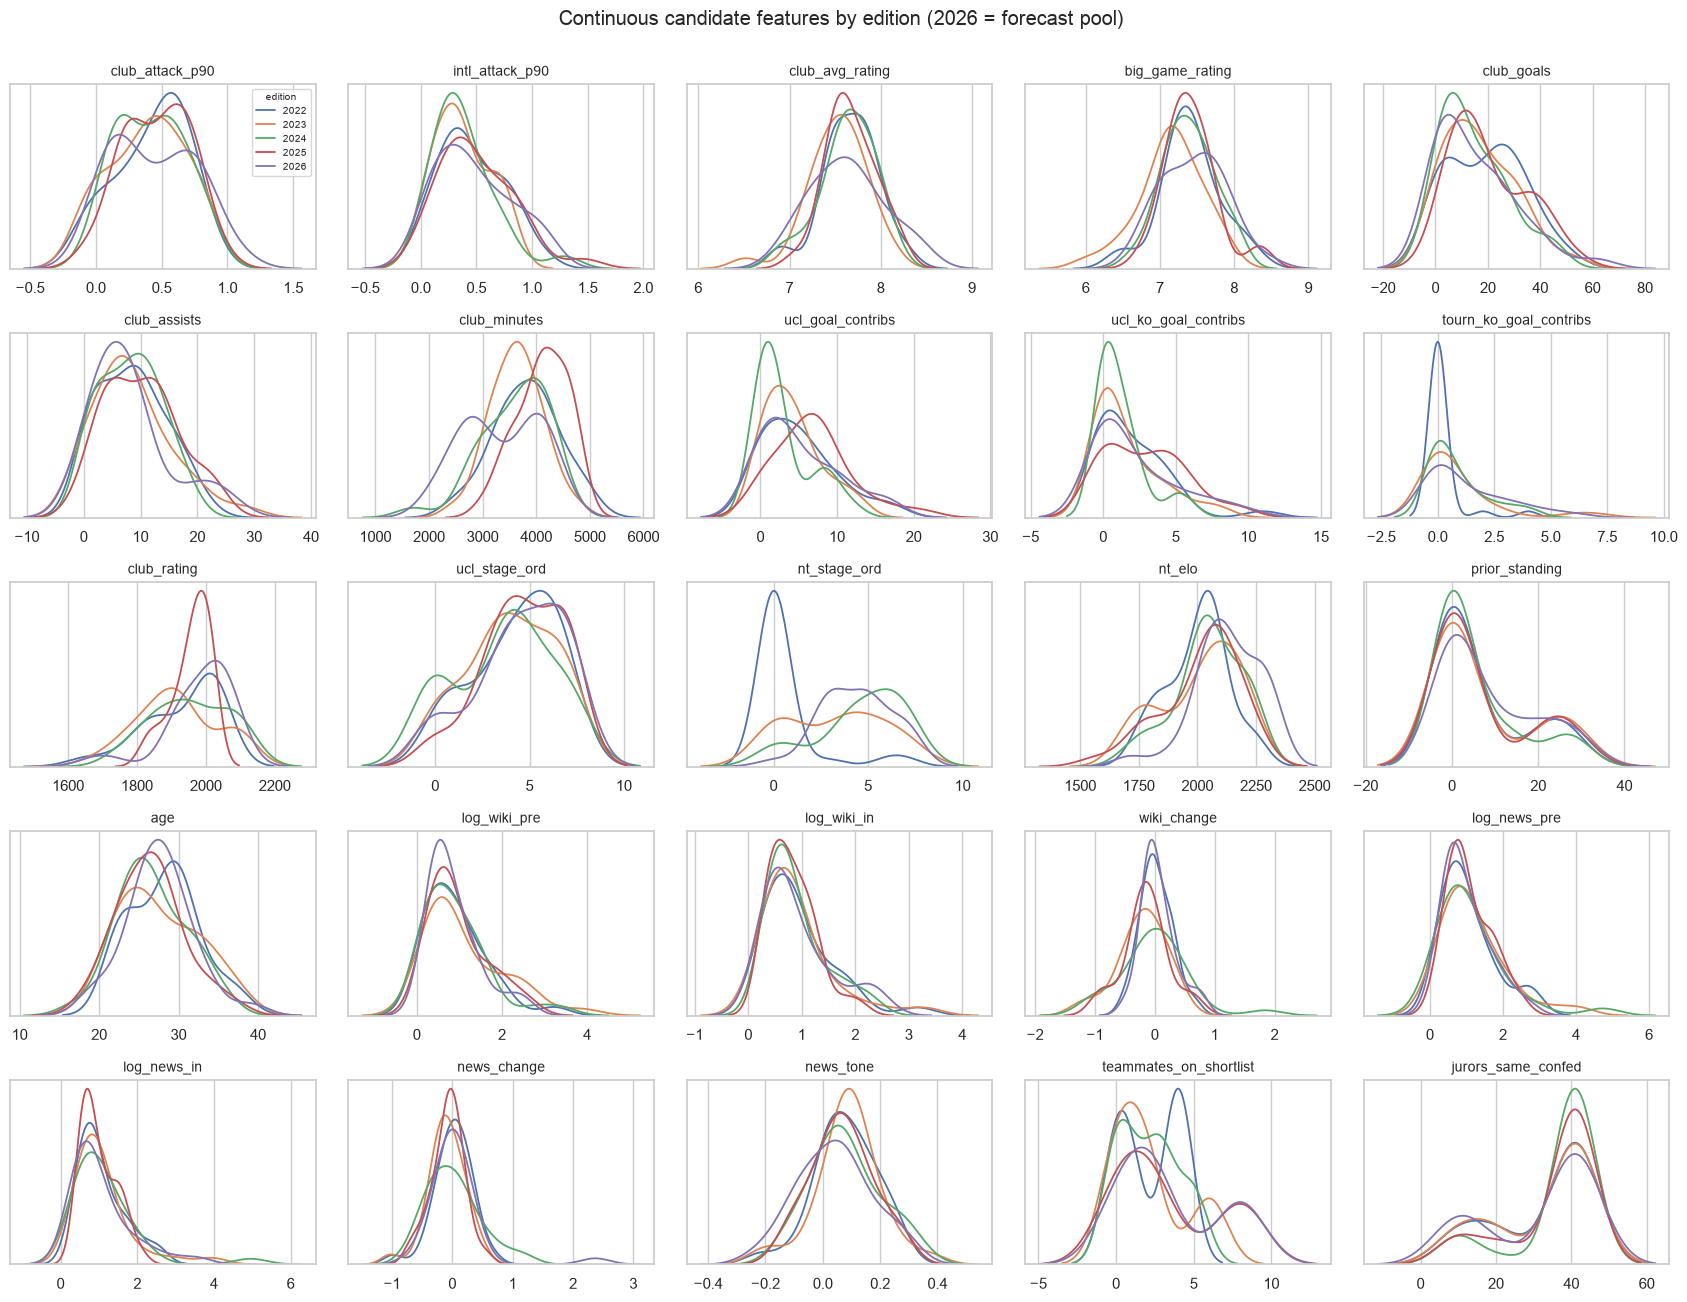

In [24]:
continuous = [f for f in FEATURES if raw[f].nunique() > 6]
n_cols = 5
n_rows = int(np.ceil(len(continuous) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.4 * n_cols, 2.6 * n_rows))
for ax, f in zip(axes.ravel(), continuous):
    for ed, g in raw.groupby("edition"):
        sns.kdeplot(g[f].dropna(), ax=ax, label=str(ed), linewidth=1.3, warn_singular=False)
    ax.set_title(f, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_yticks([])
for ax in axes.ravel()[len(continuous):]:
    ax.axis("off")
axes.ravel()[0].legend(fontsize=7, title="edition", title_fontsize=7)
fig.suptitle("Continuous candidate features by edition (2026 = forecast pool)", y=1.0)
plt.tight_layout()
plt.savefig("figures/eda/c_feature_distributions.png", dpi=130)
plt.show()

In [25]:
binary_like = [f for f in FEATURES if raw[f].nunique() <= 6]
share = raw.groupby("edition")[binary_like].mean().T.round(2)
share.insert(0, "group", [GROUP_OF[f] for f in share.index])
print("Mean of low-cardinality features by edition (share of nominees for 0/1 flags):")
display(share)

Mean of low-cardinality features by edition (share of nominees for 0/1 flags):


edition,group,2022,2023,2024,2025,2026
final_goal_contribs,big stage,0.70,0.87,0.97,1.50,0.53
scored_winner_in_final,big stage,0.10,0.07,0.10,0.13,0.07
tourn_award,big stage,0.13,0.17,0.10,0.23,0.10
major_titles,honors,0.20,0.37,0.47,0.30,0.53
other_honors,honors,1.00,1.20,1.00,1.47,1.43
won_ucl,honors,0.17,0.23,0.20,0.30,0.30
won_world_cup,honors,0.00,0.13,0.00,0.00,0.20
defending_winner,history,0.00,0.03,0.00,0.00,0.03
career_podiums_before,history,0.40,0.53,0.07,0.20,0.67
first_time,history,0.87,0.80,0.93,0.80,0.67


### C2. Which features move the outcome? Spearman correlation with points, *within* edition

In [26]:
def spearman_by_edition(df: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    rows = {}
    for ed, g in df.groupby("edition"):
        rows[ed] = {f: stats.spearmanr(g[f], g["points"], nan_policy="omit")[0] if g[f].nunique() > 1 else np.nan for f in features}
    return pd.DataFrame(rows)

def within_edition_rank_pct(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    return df.groupby("edition")[cols].rank(pct=True)

per_ed = spearman_by_edition(lab, FEATURES)
per_ed["mean"] = per_ed.mean(axis=1)
per_ed["n_same_sign"] = [int((np.sign(per_ed.loc[f, [2022, 2023, 2024, 2025]].dropna()) == np.sign(per_ed.loc[f, "mean"])).sum()) for f in per_ed.index]

pooled_x = within_edition_rank_pct(lab, FEATURES)
pooled_y = lab.groupby("edition")["points"].rank(pct=True)
pooled = pd.DataFrame({f: stats.spearmanr(pooled_x[f], pooled_y, nan_policy="omit") for f in FEATURES}, index=["rho_pooled", "p_value"]).T
# Benjamini-Hochberg across the screened features
order = pooled["p_value"].sort_values().index
m = len(order)
bh = (pooled.loc[order, "p_value"] * m / np.arange(1, m + 1))[::-1].cummin()[::-1].clip(upper=1)
pooled["p_BH"] = bh
screen = per_ed.join(pooled).join(pd.Series(GROUP_OF, name="group"))
screen["abs_mean"] = screen["mean"].abs()
screen = screen.sort_values("abs_mean", ascending=False)
display(screen[["group", 2022, 2023, 2024, 2025, "mean", "n_same_sign", "rho_pooled", "p_value", "p_BH"]].round(3))

,group,2022,2023,2024,2025,mean,n_same_sign,rho_pooled,p_value,p_BH
log_wiki_in,attention,0.596,0.558,0.735,0.405,0.573,4,0.569,0.000,0.000
log_news_in,attention,0.577,0.701,0.711,0.304,0.573,4,0.570,0.000,0.000
other_honors,honors,0.294,0.645,0.254,0.593,0.446,4,0.469,0.000,0.000
log_wiki_pre,attention,0.479,0.539,0.553,0.187,0.439,4,0.436,0.000,0.000
ucl_goal_contribs,big stage,0.347,0.670,0.530,0.174,0.430,4,0.420,0.000,0.000
log_news_pre,attention,0.432,0.588,0.615,0.053,0.422,4,0.420,0.000,0.000
major_titles,honors,0.480,0.416,0.443,0.345,0.421,4,0.366,0.000,0.000
final_goal_contribs,big stage,0.226,0.354,0.541,0.520,0.410,4,0.409,0.000,0.000
ucl_ko_goal_contribs,big stage,0.451,0.464,0.455,0.253,0.406,4,0.378,0.000,0.000
club_avg_rating,performance,0.282,0.423,0.388,0.505,0.400,4,0.391,0.000,0.000


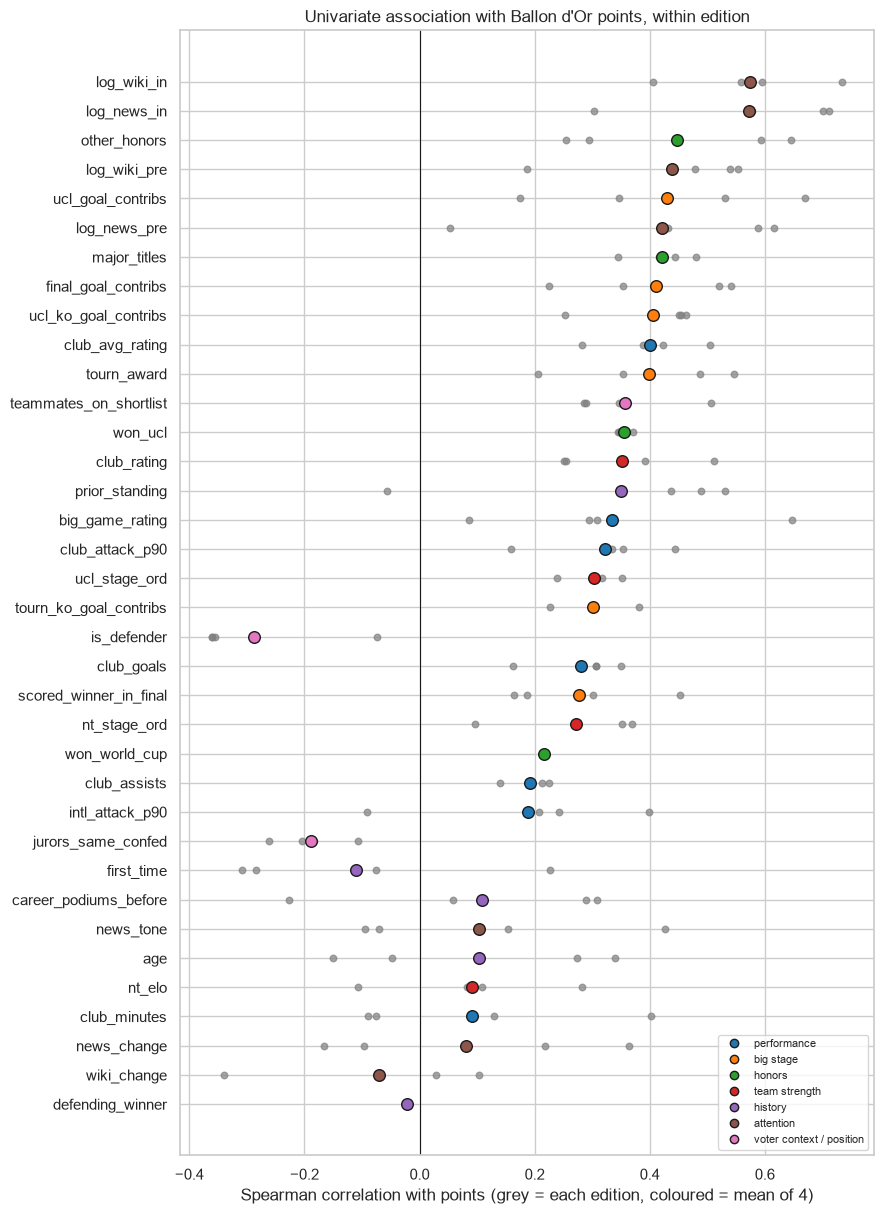

In [27]:
order = screen.index[::-1]
palette = dict(zip(GROUPS, sns.color_palette("tab10", len(GROUPS))))
fig, ax = plt.subplots(figsize=(9, 0.3 * len(order) + 1.5))
for i, f in enumerate(order):
    vals = screen.loc[f, [2022, 2023, 2024, 2025]].astype(float)
    ax.scatter(vals, [i] * len(vals), s=22, color="grey", alpha=0.7, zorder=2)
    ax.scatter(screen.loc[f, "mean"], i, s=70, color=palette[GROUP_OF[f]], edgecolor="k", zorder=3)
ax.axvline(0, color="k", linewidth=0.8)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel("Spearman correlation with points (grey = each edition, coloured = mean of 4)")
ax.set_title("Univariate association with Ballon d'Or points, within edition")
handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=c, markeredgecolor="k", label=g) for g, c in palette.items()]
ax.legend(handles=handles, loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("figures/eda/c_spearman_vs_points.png", dpi=140)
plt.show()

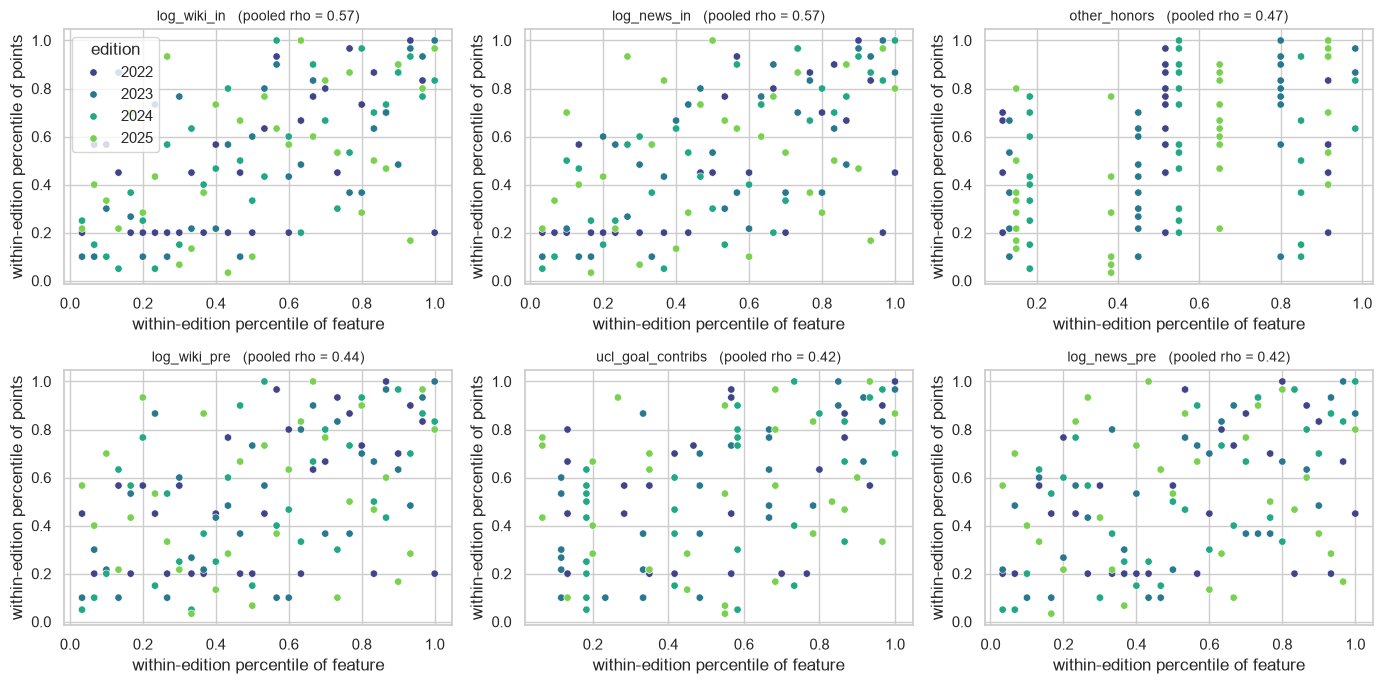

In [28]:
top = screen.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), top):
    sns.scatterplot(x=pooled_x[f], y=pooled_y, hue=lab["edition"].astype(str), ax=ax, s=28, palette="viridis", legend=(f == top[0]))
    ax.set_title(f"{f}   (pooled rho = {screen.loc[f, 'rho_pooled']:.2f})", fontsize=10)
    ax.set_xlabel("within-edition percentile of feature")
    ax.set_ylabel("within-edition percentile of points")
plt.tight_layout()
plt.savefig("figures/eda/c_top_features_scatter.png", dpi=130)
plt.show()

Group-level view: do categorical/ordinal drivers separate high and low vote-getters?

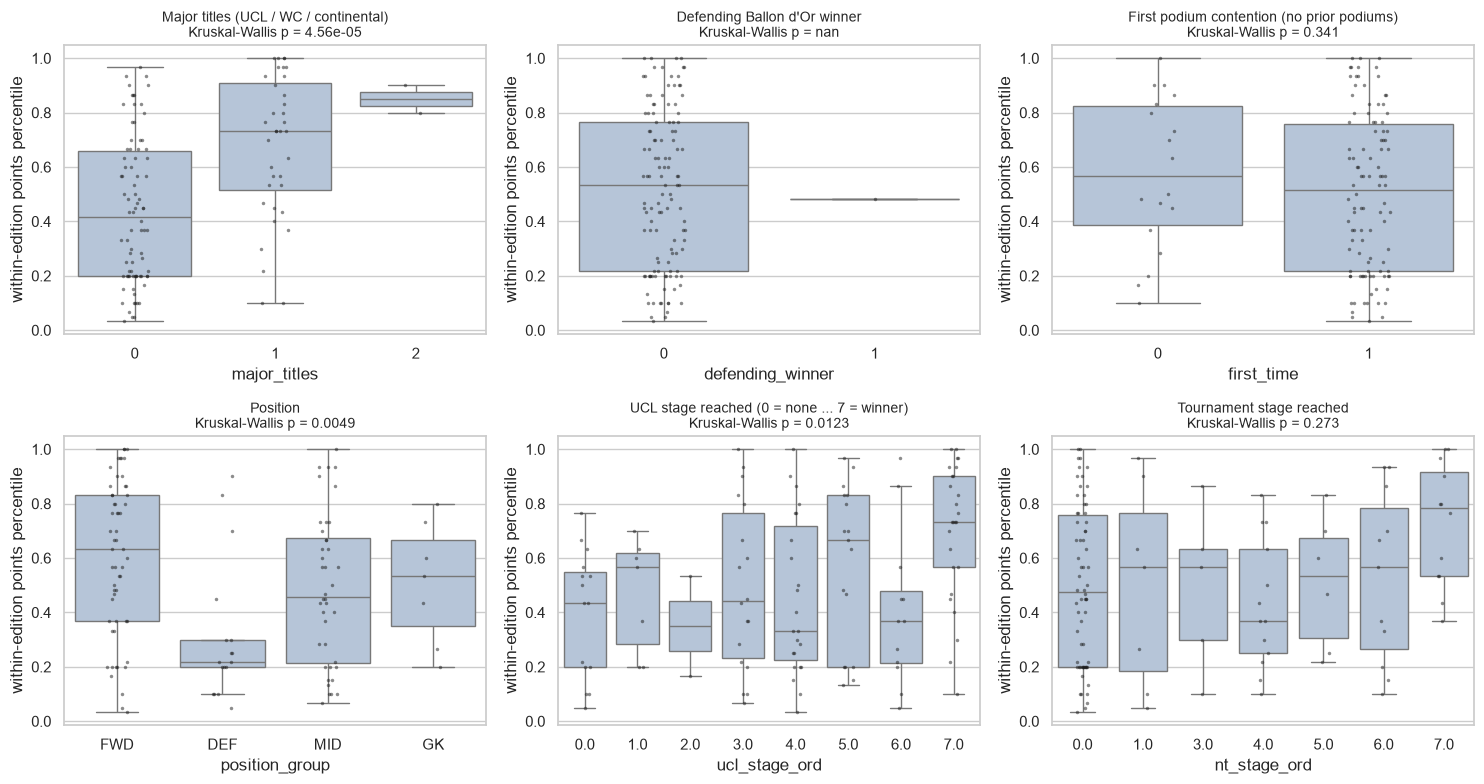

,split,group_sizes,kruskal_H,p_value
0,major_titles,"[82, 36, 2]",19.9924,0.0000
1,defending_winner,"[119, 1]",NaN,NaN
2,first_time,"[18, 102]",0.9076,0.3407
3,position_group,"[17, 56, 7, 40]",12.8822,0.0049
4,ucl_stage_ord,"[15, 7, 2, 18, 23, 17, 12, 26]",17.9344,0.0123
5,nt_stage_ord,"[66, 7, 5, 13, 6, 11, 12]",7.5462,0.2733


In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
lab_pct = lab.assign(points_pct=pooled_y)
panels = [("major_titles", "Major titles (UCL / WC / continental)"), ("defending_winner", "Defending Ballon d'Or winner"),
          ("first_time", "First podium contention (no prior podiums)"), ("position_group", "Position"),
          ("ucl_stage_ord", "UCL stage reached (0 = none ... 7 = winner)"), ("nt_stage_ord", "Tournament stage reached")]
kw_rows = []
for ax, (col, title) in zip(axes.ravel(), panels):
    sns.boxplot(data=lab_pct, x=col, y="points_pct", ax=ax, color="lightsteelblue", fliersize=0)
    sns.stripplot(data=lab_pct, x=col, y="points_pct", ax=ax, color="k", size=2.5, alpha=0.5)
    groups = [g["points_pct"].values for _, g in lab_pct.groupby(col)]
    h, p = stats.kruskal(*groups) if len(groups) > 1 and sum(len(g) >= 2 for g in groups) > 1 else (np.nan, np.nan)
    kw_rows.append({"split": col, "group_sizes": [len(g) for g in groups], "kruskal_H": h, "p_value": p})
    ax.set_title(f"{title}\nKruskal-Wallis p = {p:.3g}", fontsize=10)
    ax.set_ylabel("within-edition points percentile")
plt.tight_layout()
plt.savefig("figures/eda/c_points_by_group.png", dpi=130)
plt.show()
display(pd.DataFrame(kw_rows).round(4))

### C3. How much do the candidate features overlap? Correlation and collinearity

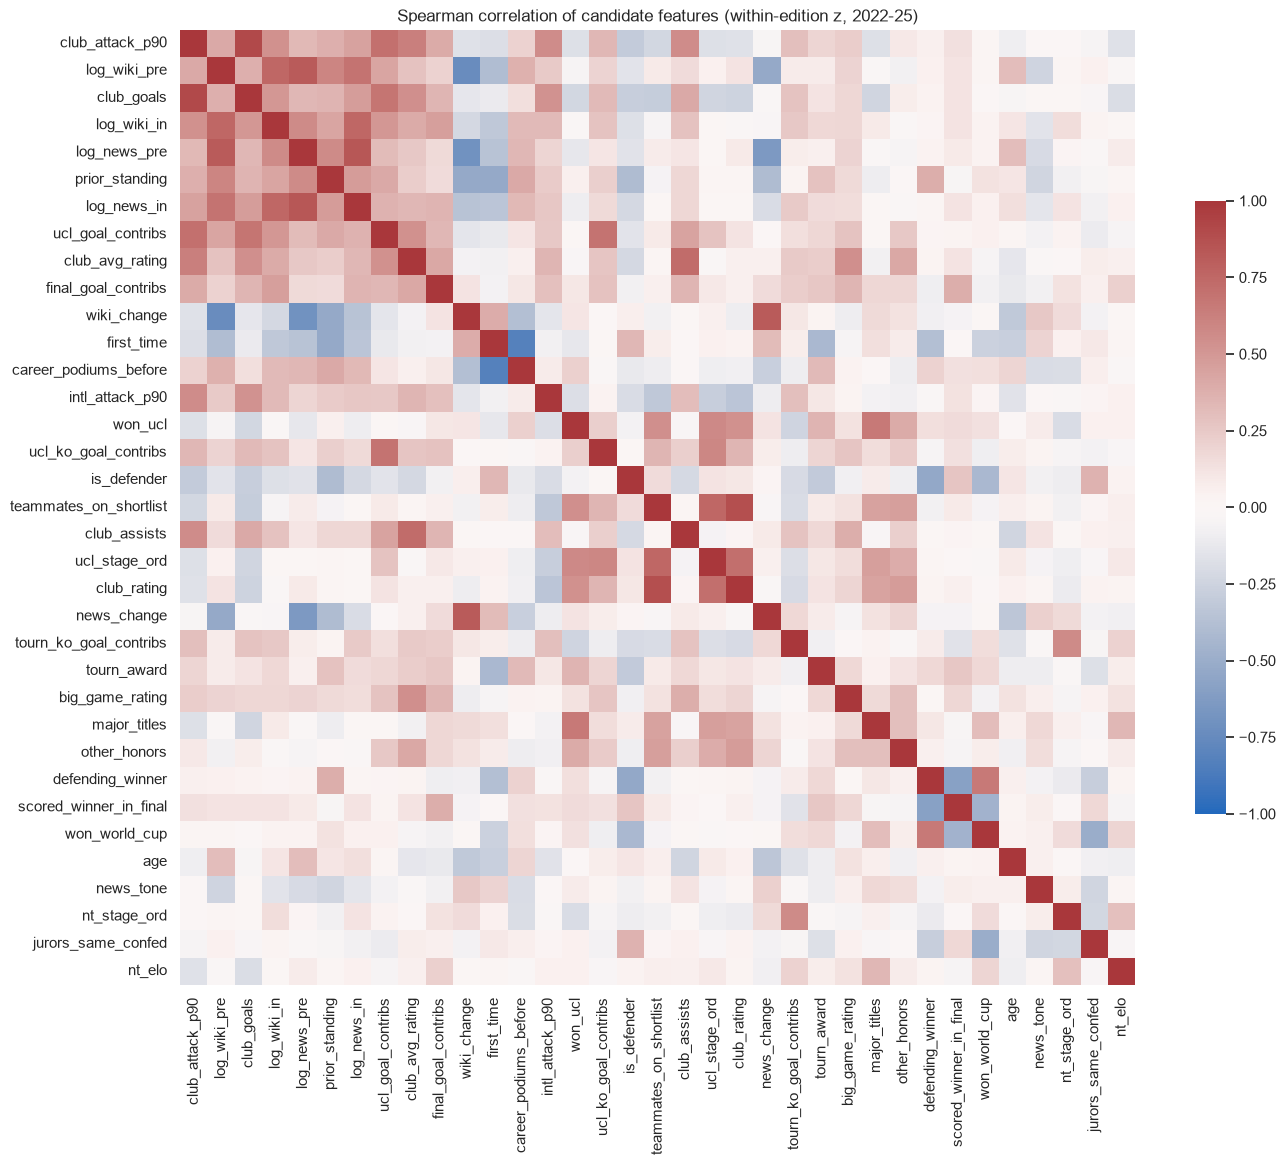

Strongest pairs (|rho| >= 0.6), descriptive only:


,feature_a,feature_b,rho
0,club_attack_p90,club_goals,0.91
1,club_rating,teammates_on_shortlist,0.88
2,log_news_pre,log_news_in,0.84
3,career_podiums_before,first_time,-0.83
4,wiki_change,news_change,0.82
5,log_wiki_pre,log_news_pre,0.81
6,ucl_stage_ord,teammates_on_shortlist,0.76
7,log_wiki_pre,log_wiki_in,0.75
8,log_wiki_in,log_news_in,0.75
9,log_wiki_pre,wiki_change,-0.74


In [30]:
def within_edition_z(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    g = df.groupby("edition")[cols]
    z = (df[cols] - g.transform("mean")) / g.transform("std", ddof=1)
    return z.fillna(0.0)

Z_FEATURES = [f for f in FEATURES if f not in ("club_minutes",)]
Z = within_edition_z(lab, Z_FEATURES)
corr = Z.corr(method="spearman")
order = corr.abs().sum().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr.loc[order, order], cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, annot=False, square=True, cbar_kws={"shrink": 0.6})
ax.set_title("Spearman correlation of candidate features (within-edition z, 2022-25)")
plt.tight_layout()
plt.savefig("figures/eda/c_feature_correlation.png", dpi=130)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho").reset_index()
pairs.columns = ["feature_a", "feature_b", "rho"]
print("Strongest pairs (|rho| >= 0.6), descriptive only:")
display(pairs[pairs["rho"].abs() >= 0.6].sort_values("rho", key=lambda s: -s.abs()).round(2).reset_index(drop=True))

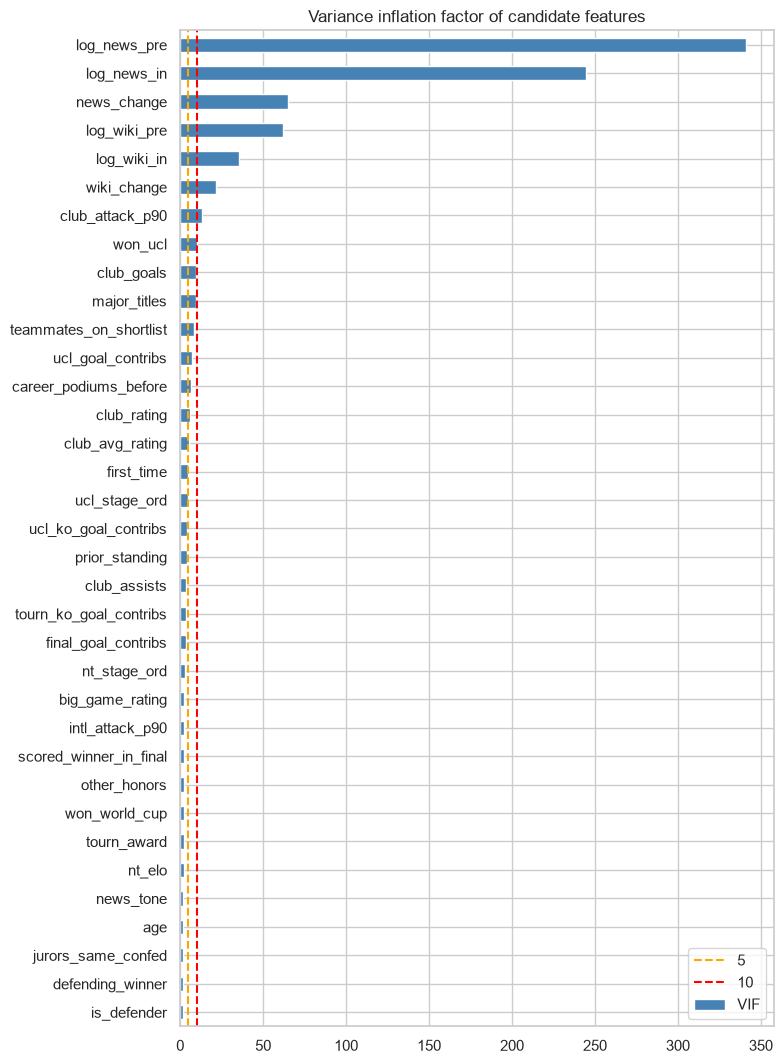

,VIF
log_news_pre,340.9
log_news_in,244.3
news_change,65.0
log_wiki_pre,62.1
log_wiki_in,35.6
wiki_change,21.8
club_attack_p90,13.1
won_ucl,9.9
club_goals,9.7
major_titles,9.5


In [31]:
# Variance inflation factors on the within-edition z matrix (nothing is dropped on the basis of this)
Zc = Z.loc[:, Z.std() > 0]
inv = np.linalg.pinv(np.corrcoef(Zc.values, rowvar=False))
vif = pd.Series(np.diag(inv), index=Zc.columns, name="VIF").sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 0.28 * len(vif) + 1))
vif[::-1].plot.barh(ax=ax, color="steelblue")
ax.axvline(5, color="orange", linestyle="--", label="5")
ax.axvline(10, color="red", linestyle="--", label="10")
ax.set_title("Variance inflation factor of candidate features")
ax.legend()
plt.tight_layout()
plt.savefig("figures/eda/c_vif.png", dpi=130)
plt.show()
display(vif.head(10).round(1).to_frame())

### C4. PCA on the within-edition standardised candidate features
PCA is used to see the *structure* of the data (how many independent dimensions there are, and what they mean) and how each component relates to points. It is unsupervised and is not a feature-selection step.

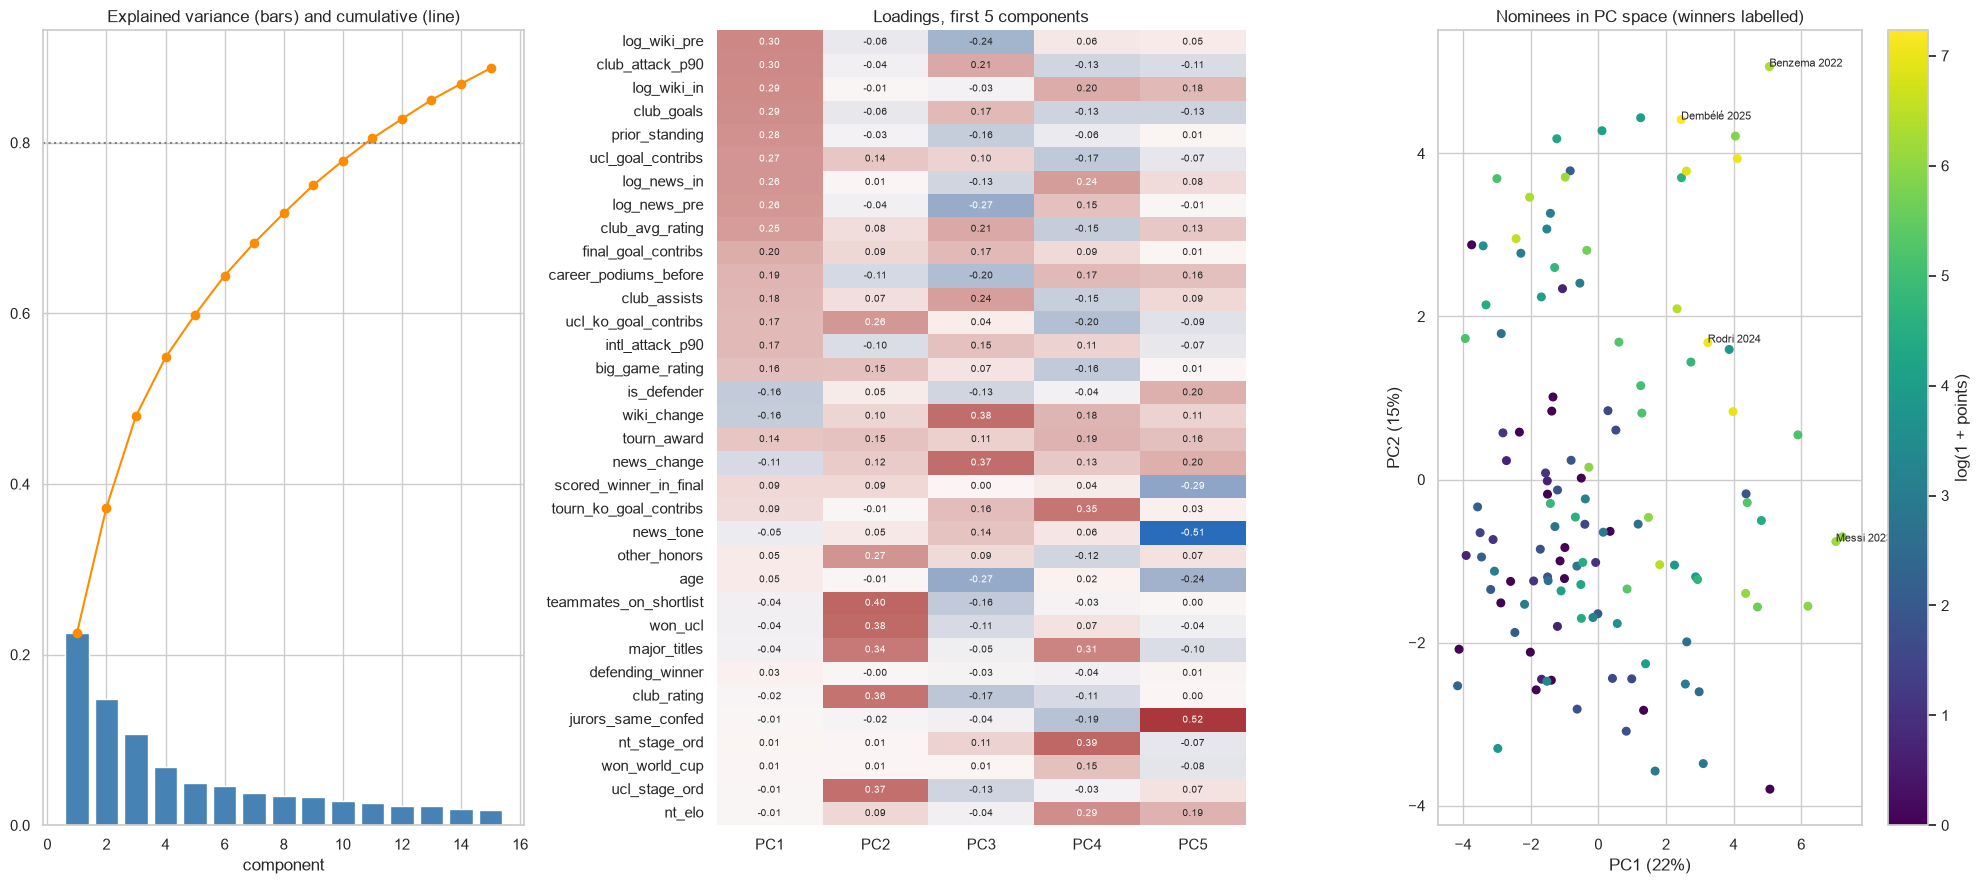

11 components reach 80% of variance out of 34 standardised features.


,variance_%,spearman_vs_points,top_loadings
PC1,22.5,0.46,"log_wiki_pre, club_attack_p90, log_wiki_in, cl..."
PC2,14.7,0.38,"teammates_on_shortlist, won_ucl, ucl_stage_ord..."
PC3,10.7,0.03,"wiki_change, news_change, age, log_news_pre"
PC4,6.9,0.18,"nt_stage_ord, tourn_ko_goal_contribs, major_ti..."
PC5,5.0,-0.09,"jurors_same_confed, news_tone, scored_winner_i..."
PC6,4.6,-0.03,"nt_elo, big_game_rating, club_assists, ucl_goa..."
PC7,3.8,-0.10,"scored_winner_in_final, final_goal_contribs, t..."
PC8,3.5,-0.17,"nt_elo, jurors_same_confed, ucl_ko_goal_contri..."


In [32]:
from sklearn.decomposition import PCA

pca_cols = [c for c in Z.columns if c not in ("first_time",)]
Zp = Z[pca_cols]
pca = PCA(random_state=SEED).fit(Zp.values)
evr = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i + 1}" for i in range(len(pca.explained_variance_ratio_))])
scores = pd.DataFrame(pca.transform(Zp.values), index=Zp.index, columns=evr.index)
loadings = pd.DataFrame(pca.components_.T, index=pca_cols, columns=evr.index)

fig, axes = plt.subplots(1, 3, figsize=(20, 9), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
axes[0].bar(range(1, 16), evr.values[:15], color="steelblue")
axes[0].plot(range(1, 16), evr.cumsum().values[:15], "o-", color="darkorange")
axes[0].set_title("Explained variance (bars) and cumulative (line)")
axes[0].set_xlabel("component")
n_for_80 = int((evr.cumsum() < 0.8).sum() + 1)
axes[0].axhline(0.8, color="grey", linestyle=":")
sns.heatmap(loadings.iloc[:, :5].loc[loadings["PC1"].abs().sort_values(ascending=False).index], cmap="vlag", center=0, ax=axes[1], cbar=False, annot=True, fmt=".2f", annot_kws={"size": 7}, yticklabels=True)
axes[1].set_title("Loadings, first 5 components")
sc = axes[2].scatter(scores["PC1"], scores["PC2"], c=np.log1p(lab["points"]), cmap="viridis", s=30)
plt.colorbar(sc, ax=axes[2], label="log(1 + points)")
for idx in lab.sort_values("points", ascending=False).groupby("edition").head(1).index:
    axes[2].annotate(lab.loc[idx, "player_name"].split()[-1] + f" {lab.loc[idx, 'edition']}", (scores.loc[idx, "PC1"], scores.loc[idx, "PC2"]), fontsize=8)
axes[2].set_xlabel(f"PC1 ({evr['PC1']:.0%})")
axes[2].set_ylabel(f"PC2 ({evr['PC2']:.0%})")
axes[2].set_title("Nominees in PC space (winners labelled)")
plt.tight_layout()
plt.savefig("figures/eda/c_pca.png", dpi=130)
plt.show()
print(f"{n_for_80} components reach 80% of variance out of {len(pca_cols)} standardised features.")

pc_corr = pd.DataFrame({
    "variance_%": (evr * 100).round(1),
    "spearman_vs_points": [stats.spearmanr(scores[pc], lab["points"])[0] for pc in evr.index],
    "top_loadings": [", ".join(loadings[pc].abs().sort_values(ascending=False).head(4).index) for pc in evr.index],
}).head(8)
pc_corr["spearman_vs_points"] = pc_corr["spearman_vs_points"].round(2)
display(pc_corr)

### C5. Do the strongest raw features overlap with each other? (a first look at what a model could add)

In [33]:
# Pooled rank-regression of within-edition points percentile on a few representative inputs from each group (descriptive: standardised coefficients, not a model for use)
rep = ["club_attack_p90", "big_game_rating", "ucl_ko_goal_contribs", "major_titles", "other_honors", "club_rating", "prior_standing",
       "defending_winner", "log_wiki_pre", "wiki_change"]
X = Z[rep].copy()
X.insert(0, "const", 1.0)
y = (pooled_y - pooled_y.mean()) / pooled_y.std()
beta, *_ = np.linalg.lstsq(X.values, y.values, rcond=None)
resid = y.values - X.values @ beta
dof = len(y) - X.shape[1]
cov = (resid @ resid / dof) * np.linalg.inv(X.values.T @ X.values)
se = np.sqrt(np.diag(cov))
ols = pd.DataFrame({"coef": beta, "se": se, "t": beta / se}, index=X.columns).drop(index="const")
ols["p_value"] = 2 * stats.t.sf(ols["t"].abs(), dof)
r2 = 1 - (resid @ resid) / ((y - y.mean()) @ (y - y.mean()))
display(ols.sort_values("t", key=lambda s: -s.abs()).round(3))
print(f"R^2 = {r2:.2f} on {len(y)} rows (in-sample, descriptive; the CV in the modelling stage is the real test).")

,coef,se,t,p_value
log_wiki_pre,0.450,0.112,4.027,0.000
major_titles,0.275,0.078,3.536,0.001
wiki_change,0.324,0.097,3.346,0.001
other_honors,0.229,0.073,3.125,0.002
club_rating,0.192,0.084,2.274,0.025
prior_standing,0.209,0.098,2.128,0.036
club_attack_p90,0.120,0.082,1.464,0.146
defending_winner,-0.150,0.127,-1.182,0.240
big_game_rating,0.049,0.069,0.705,0.482
ucl_ko_goal_contribs,0.032,0.082,0.388,0.699


R^2 = 0.60 on 120 rows (in-sample, descriptive; the CV in the modelling stage is the real test).


### C6. T2-only block: do post-window signals relate to points?
Raw, un-shrunk look only. 2025 has almost no post-window minutes, so interpret with care. Feature construction (shrinkage, residualisation) comes in the preparation step.

,2022,2023,2024,2025,mean
post_attack_p90,0.459,0.486,0.338,NaN,0.428
post_minutes,-0.069,0.073,0.145,0.255,0.101
post_avg_rating,0.423,0.344,0.194,0.118,0.270
post_goal_contribs,0.301,0.395,0.212,0.131,0.260
wiki_rate_change,-0.080,-0.413,-0.124,0.093,-0.131
wiki_final14_vs_post,0.165,-0.057,0.364,-0.122,0.087
news_post_vs_in,-0.426,-0.417,-0.168,0.135,-0.219
post_transfer,-0.044,-0.267,-0.327,0.011,-0.157
post_injury,0.381,0.037,0.204,-0.067,0.139


wiki_rate_change here is un-normalised by window length: days_in is not available, so this is a rough level shift only.


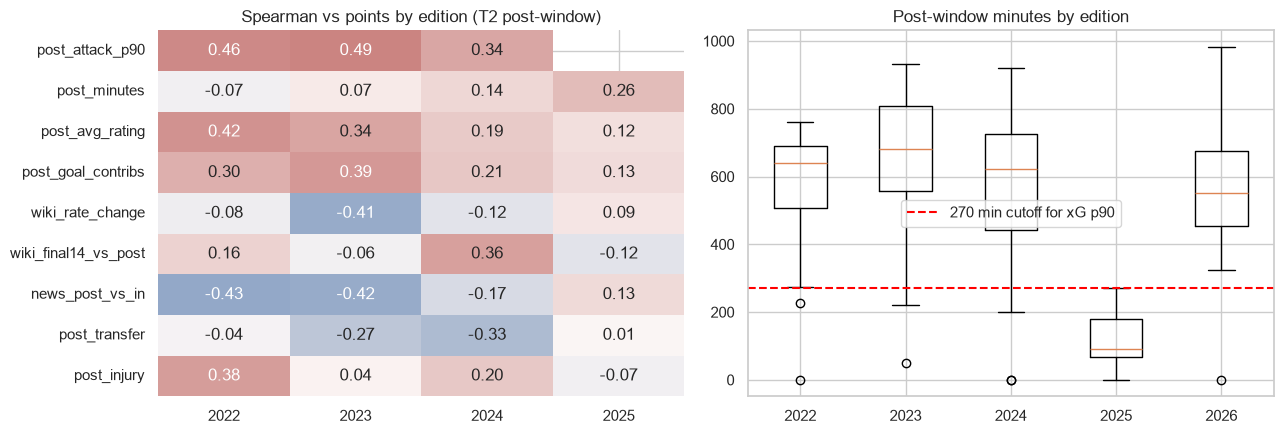

post_transfer / post_injury counts by edition:


,post_transfer,post_injury
edition,,
2022,1,2
2023,4,10
2024,3,12
2025,1,6
2026,2,4


In [34]:
t2l = t2[t2["edition"] < FORECAST_EDITION].copy()
post = pd.DataFrame({
    "edition": t2l["edition"],
    "points": t2l["bdo_points"],
    "post_attack_p90": t2l["post_npxg_xa_p90_opp_adj"],
    "post_minutes": t2l["post_minutes"],
    "post_avg_rating": t2l["post_avg_rating"],
    "post_goal_contribs": t2l["post_goal_contribs"],
    "wiki_rate_change": np.log(t2l["wiki_views_post_juror_w"] / (t2l["snapshot_date"].pipe(pd.to_datetime) - t2l["edition"].map(EDITION_FACTS["window_end"])).dt.days)
                         - np.log(t2l["wiki_views_in_juror_w"]),
    "wiki_final14_vs_post": np.log(t2l["wiki_views_final14_juror_w"] / 14) - np.log(t2l["wiki_views_post_juror_w"]
                         / (t2l["snapshot_date"].pipe(pd.to_datetime) - t2l["edition"].map(EDITION_FACTS["window_end"])).dt.days),
    "news_post_vs_in": np.log1p(t2l["news_vol_post_juror_w"]) - np.log1p(t2l["news_vol_in_juror_w"]),
    "post_transfer": t2l["post_transfer"].astype(int),
    "post_injury": t2l["post_injury"].astype(int),
})
note = "wiki_rate_change here is un-normalised by window length: days_in is not available, so this is a rough level shift only."
post_feats = [c for c in post.columns if c not in ("edition", "points")]
post_corr = spearman_by_edition(post, post_feats)
post_corr["mean"] = post_corr.mean(axis=1)
display(post_corr.round(3))
print(note)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(post_corr.drop(columns="mean"), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-0.8, vmax=0.8, ax=axes[0], cbar=False)
axes[0].set_title("Spearman vs points by edition (T2 post-window)")
post_minutes_by_ed = t2.groupby("edition")["post_minutes"].apply(list)
axes[1].boxplot([v for v in post_minutes_by_ed.values], tick_labels=list(post_minutes_by_ed.index))
axes[1].axhline(270, color="red", linestyle="--", label="270 min cutoff for xG p90")
axes[1].set_title("Post-window minutes by edition")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/eda/c_post_window.png", dpi=130)
plt.show()
print("post_transfer / post_injury counts by edition:")
display(t2.groupby("edition")[["post_transfer", "post_injury"]].sum())

## D. Attention before, during and after the window — is there recency bias?

Question: does a player who is *hyped in the weeks leading up to the vote* get more points than their season (and their baseline fame) justify?

Attention columns (juror-weighted Wikipedia views and news volume) come in four time slices: `pre` (before the window), `in` (during the window), `post` (window end -> 3 days before the vote deadline, T2 only) and `final14` (the last 14 days of that period, Wikipedia only).

Method notes:
- All attention values are `log`-transformed, then **standardised within edition**. Dividing by period length (days) only shifts the log by a constant within an edition, so within-edition ranks and z-scores are unaffected; this is why the missing window start dates do not matter here.
- `final_spike` = log daily rate of the last 14 days minus log daily rate of the whole post-window period (spec P3). Positive = attention accelerating into the vote.
- Attention is **not independent of performance**: good seasons attract views. So the key test is a *partial* correlation: does recent attention still relate to points after controlling for performance, honors, team strength and prior standing (and for the player's baseline fame)?
- Only the 120 labelled rows are used. Descriptive/exploratory; the pre-registered attention tests come later in the modelling stage. 2025's post-window is only 40 days.

In [35]:
days_post = (pd.to_datetime(t2["snapshot_date"]) - t2["edition"].map(EDITION_FACTS["window_end"])).dt.days
att = pd.DataFrame({
    "edition": t2["edition"],
    "player_name": t2["player_name"],
    "points": t2["bdo_points"],
    "wiki_pre": np.log(t2["wiki_views_pre_juror_w"]),
    "wiki_in": np.log(t2["wiki_views_in_juror_w"]),
    "wiki_post": np.log(t2["wiki_views_post_juror_w"] / days_post),
    "wiki_final14": np.log(t2["wiki_views_final14_juror_w"] / 14),
    "news_pre": np.log(t2["news_vol_pre_juror_w"]),
    "news_in": np.log(t2["news_vol_in_juror_w"]),
    "news_post": np.log(t2["news_vol_post_juror_w"] / days_post),
})
att["final_spike"] = att["wiki_final14"] - att["wiki_post"]
ATT_COLS = [c for c in att.columns if c not in ("edition", "player_name", "points")]
att_lab = att[att["edition"] < FORECAST_EDITION].copy()
att_z = within_edition_z(att, ATT_COLS)
att_lab_z = att_z.loc[att_lab.index]
print("any non-finite attention values:", int((~np.isfinite(att[ATT_COLS])).sum().sum()))
display(att_lab[ATT_COLS].describe().T.round(2))

any non-finite attention values: 0


,count,mean,std,min,25%,50%,75%,max
wiki_pre,120.0,0.21,1.30,-3.23,-0.62,0.12,1.11,3.82
wiki_in,120.0,0.19,0.93,-1.88,-0.43,0.11,0.61,3.24
wiki_post,120.0,-3.74,0.93,-5.43,-4.38,-3.87,-3.16,-1.13
wiki_final14,120.0,-2.47,0.94,-4.18,-3.10,-2.54,-1.92,0.17
news_pre,120.0,0.46,1.27,-3.54,-0.23,0.40,1.26,4.71
news_in,120.0,0.52,0.94,-0.91,-0.10,0.36,1.05,4.94
news_post,120.0,-3.53,0.77,-5.23,-4.05,-3.53,-3.07,-1.34
final_spike,120.0,1.27,0.38,-0.41,1.08,1.27,1.52,1.95


### D1. Persistence: does attention in one period predict attention in the next?

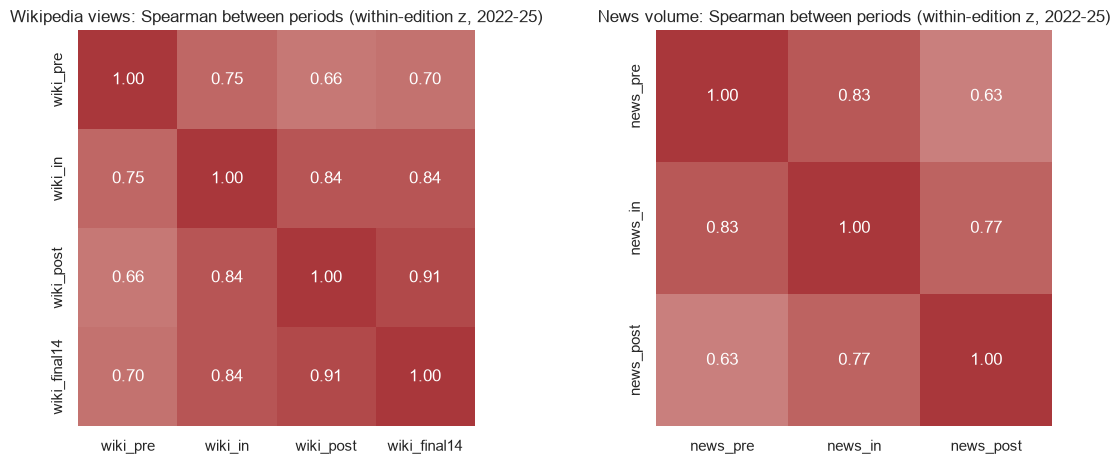

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
wiki_cols = ["wiki_pre", "wiki_in", "wiki_post", "wiki_final14"]
news_cols = ["news_pre", "news_in", "news_post"]
for ax, cols, title in zip(axes, (wiki_cols, news_cols), ("Wikipedia views", "News volume")):
    c = att_lab_z[cols].corr(method="spearman")
    sns.heatmap(c, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar=False, square=True)
    ax.set_title(f"{title}: Spearman between periods (within-edition z, 2022-25)")
plt.tight_layout()
plt.savefig("figures/eda/d_attention_persistence.png", dpi=130)
plt.show()

### D2. Attention in each period vs points (within-edition Spearman)

,2022,2023,2024,2025,mean,pooled_rho,pooled_p
wiki_pre,0.479,0.539,0.553,0.187,0.439,0.439,0.000
wiki_in,0.596,0.558,0.735,0.405,0.573,0.576,0.000
wiki_post,0.493,0.428,0.602,0.385,0.477,0.477,0.000
wiki_final14,0.545,0.472,0.701,0.356,0.519,0.504,0.000
news_pre,0.432,0.588,0.615,0.053,0.422,0.414,0.000
news_in,0.577,0.701,0.711,0.304,0.573,0.556,0.000
news_post,0.283,0.409,0.682,0.287,0.415,0.438,0.000
final_spike,0.165,-0.057,0.364,-0.122,0.087,0.091,0.322


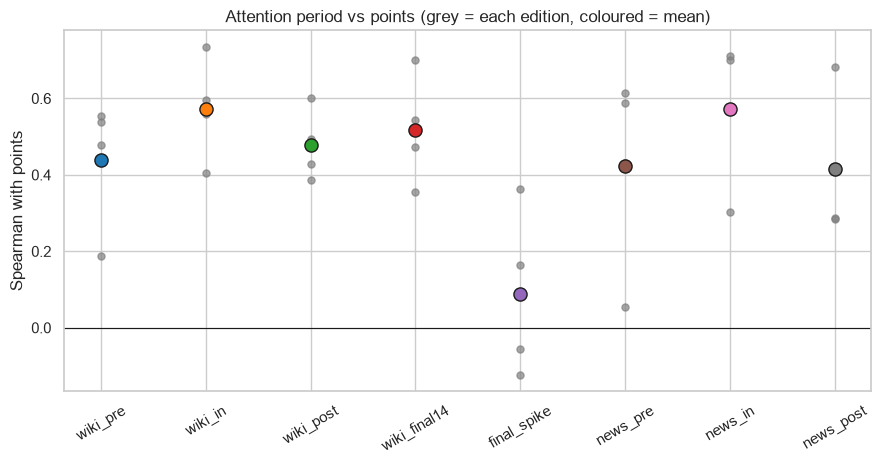

In [37]:
def spearman_by_edition_frame(df: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    return pd.DataFrame({ed: {f: stats.spearmanr(g[f], g["points"])[0] for f in features} for ed, g in df.groupby("edition")})

att_corr = spearman_by_edition_frame(att_lab, ATT_COLS)
att_corr["mean"] = att_corr.mean(axis=1)
pooled_att_x = att_lab_z[ATT_COLS]
pooled_att_y = att_lab.groupby("edition")["points"].rank(pct=True)
att_corr["pooled_rho"] = [stats.spearmanr(pooled_att_x[f], pooled_att_y)[0] for f in att_corr.index]
att_corr["pooled_p"] = [stats.spearmanr(pooled_att_x[f], pooled_att_y)[1] for f in att_corr.index]
display(att_corr.round(3))

fig, ax = plt.subplots(figsize=(9, 4.8))
order = ["wiki_pre", "wiki_in", "wiki_post", "wiki_final14", "final_spike", "news_pre", "news_in", "news_post"]
for i, f in enumerate(order):
    vals = att_corr.loc[f, [2022, 2023, 2024, 2025]].astype(float)
    ax.scatter([i] * 4, vals, color="grey", alpha=0.7, s=26)
    ax.scatter(i, att_corr.loc[f, "mean"], s=90, color=sns.color_palette("tab10")[i % 10], edgecolor="k", zorder=3)
ax.axhline(0, color="k", linewidth=0.8)
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=30)
ax.set_ylabel("Spearman with points")
ax.set_title("Attention period vs points (grey = each edition, coloured = mean)")
plt.tight_layout()
plt.savefig("figures/eda/d_attention_vs_points.png", dpi=130)
plt.show()

### D3. The recency test: partial correlations after controlling for performance, honors, team strength and prior standing
Controls (within-edition z): attack rate, big-game rating, UCL knockout contributions, major titles, other honors, club rating, prior standing. Set B additionally controls for baseline fame (`wiki_pre`) and in-window attention (`wiki_in`).

,controls,attention,raw_rho,partial_rho,ci90_lo,ci90_hi,ed2022,ed2023,ed2024,ed2025,n_pos_editions
0,A,wiki_post,0.477,0.416,0.268,0.535,0.059,0.244,0.386,0.507,4
1,A,wiki_final14,0.504,0.412,0.271,0.531,0.232,0.430,0.453,0.436,4
2,A,final_spike,0.091,0.025,-0.117,0.182,0.154,0.275,0.055,0.017,4
3,A,news_post,0.438,0.329,0.162,0.478,0.010,0.091,0.446,0.374,4
4,B,wiki_post,0.477,0.131,-0.032,0.273,0.004,-0.031,-0.070,0.338,2
5,B,wiki_final14,0.504,0.133,-0.020,0.276,0.193,0.235,0.134,0.196,4
6,B,final_spike,0.091,0.032,-0.126,0.190,0.163,0.281,0.080,0.025,4
7,B,news_post,0.438,0.158,-0.007,0.318,-0.015,0.099,0.178,0.180,3


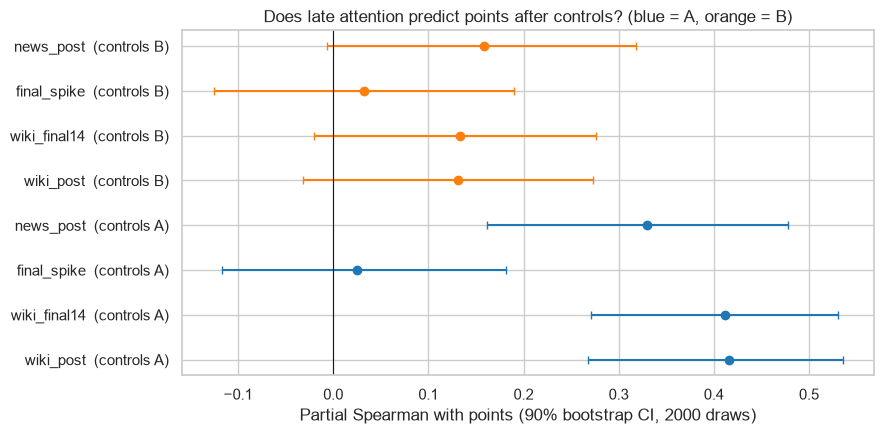

In [38]:
CONTROLS_A = ["club_attack_p90", "big_game_rating", "ucl_ko_goal_contribs", "major_titles", "other_honors", "club_rating", "prior_standing"]
Zc_all = within_edition_z(raw, CONTROLS_A)
Zc_lab = Zc_all.loc[att_lab.index]
y_pct = pooled_att_y.values

def residualise(target: np.ndarray, controls: np.ndarray) -> np.ndarray:
    design = np.column_stack([np.ones(len(controls)), controls])
    beta, *_ = np.linalg.lstsq(design, target, rcond=None)
    return target - design @ beta

def partial_spearman(x: np.ndarray, y: np.ndarray, controls: np.ndarray) -> float:
    rx = stats.rankdata(x)
    ry = stats.rankdata(y)
    return float(np.corrcoef(residualise(rx, controls), residualise(ry, controls))[0, 1])

def bootstrap_ci(x: np.ndarray, y: np.ndarray, controls: np.ndarray, n_boot: int, rng: np.random.Generator) -> tuple[float, float]:
    n = len(x)
    draws = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        draws[b] = partial_spearman(x[idx], y[idx], controls[idx])
    return float(np.percentile(draws, 5)), float(np.percentile(draws, 95))

rng = np.random.default_rng(SEED)
N_BOOT = 2000
control_sets = {
    "A: performance + honors + team + prior standing": Zc_lab.values,
    "B: A + baseline fame (wiki_pre) + in-window attention (wiki_in)": np.column_stack([Zc_lab.values, att_lab_z[["wiki_pre", "wiki_in"]].values]),
}
tests = ["wiki_post", "wiki_final14", "final_spike", "news_post"]
rows = []
for name, ctrl in control_sets.items():
    for f in tests:
        x = att_lab_z[f].values
        raw_rho = stats.spearmanr(x, y_pct)[0]
        part = partial_spearman(x, y_pct, ctrl)
        lo, hi = bootstrap_ci(x, y_pct, ctrl, N_BOOT, rng)
        per_ed = []
        for ed in (2022, 2023, 2024, 2025):
            m = (att_lab["edition"] == ed).values
            per_ed.append(partial_spearman(x[m], att_lab["points"].values[m], ctrl[m]))
        rows.append({"controls": name[:1], "attention": f, "raw_rho": raw_rho, "partial_rho": part, "ci90_lo": lo, "ci90_hi": hi,
                     **{f"ed{ed}": v for ed, v in zip((2022, 2023, 2024, 2025), per_ed)}, "n_pos_editions": int(sum(v > 0 for v in per_ed))})
partial_tbl = pd.DataFrame(rows)
display(partial_tbl.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, r in partial_tbl.iterrows():
    colour = "tab:blue" if r["controls"] == "A" else "tab:orange"
    ax.errorbar(r["partial_rho"], i, xerr=[[r["partial_rho"] - r["ci90_lo"]], [r["ci90_hi"] - r["partial_rho"]]], fmt="o", color=colour, capsize=3)
ax.axvline(0, color="k", linewidth=0.8)
ax.set_yticks(range(len(partial_tbl)))
ax.set_yticklabels([f"{r['attention']}  (controls {r['controls']})" for _, r in partial_tbl.iterrows()])
ax.set_xlabel("Partial Spearman with points (90% bootstrap CI, 2000 draws)")
ax.set_title("Does late attention predict points after controls? (blue = A, orange = B)")
plt.tight_layout()
plt.savefig("figures/eda/d_partial_recency.png", dpi=130)
plt.show()

In [39]:
# Incremental explanatory power: pooled OLS of within-edition points percentile on blocks of predictors (in-sample, descriptive)
y_std = (y_pct - y_pct.mean()) / y_pct.std()

def fit_r2(design_cols: np.ndarray) -> tuple[float, np.ndarray, np.ndarray]:
    design = np.column_stack([np.ones(len(design_cols)), design_cols])
    beta, *_ = np.linalg.lstsq(design, y_std, rcond=None)
    resid = y_std - design @ beta
    return 1 - resid @ resid / (y_std @ y_std), resid, design

blocks = {
    "controls A": Zc_lab.values,
    "+ pre-window attention (wiki_pre, news_pre)": att_lab_z[["wiki_pre", "news_pre"]].values,
    "+ in-window attention (wiki_in, news_in)": att_lab_z[["wiki_in", "news_in"]].values,
    "+ post-window attention (wiki_post, news_post)": att_lab_z[["wiki_post", "news_post"]].values,
    "+ final-14-day spike (final_spike)": att_lab_z[["final_spike"]].values,
}
cum = None
prev_r2, prev_k, rows = 0.0, 0, []
n = len(y_std)
for name, cols in blocks.items():
    cum = cols if cum is None else np.column_stack([cum, cols])
    r2, _, design = fit_r2(cum)
    k = design.shape[1]
    added = k - prev_k - (1 if prev_k == 0 else 0)
    if prev_k == 0:
        f_stat, p = np.nan, np.nan
    else:
        f_stat = ((r2 - prev_r2) / (k - prev_k)) / ((1 - r2) / (n - k))
        p = stats.f.sf(f_stat, k - prev_k, n - k)
    rows.append({"step": name, "R2": r2, "delta_R2": r2 - prev_r2, "F": f_stat, "p_value": p})
    prev_r2, prev_k = r2, k
inc = pd.DataFrame(rows)
display(inc.round(3))

,step,R2,delta_R2,F,p_value
0,controls A,0.525,0.525,NaN,NaN
1,"+ pre-window attention (wiki_pre, news_pre)",0.575,0.050,6.504,0.002
2,"+ in-window attention (wiki_in, news_in)",0.645,0.070,10.690,0.000
3,"+ post-window attention (wiki_post, news_post)",0.653,0.008,1.182,0.311
4,+ final-14-day spike (final_spike),0.654,0.001,0.443,0.507


### D4. Who got hyped into the vote? Biggest late risers and fallers and how they finished

final_spike (log ratio) for the actual top 3 vs the rest, by edition:


count         mean        median       
top3    False True   False  True   False  True 
edition                                        
2022       27     3  1.247  1.250  1.292  1.265
2023       27     3  1.336  1.168  1.349  1.258
2024       27     3  1.423  1.680  1.459  1.591
2025       27     3  1.061  1.048  1.073  1.143

Mann-Whitney (z-scored spike, pooled top-3 vs rest): U = 649, p = 0.997

Top 3 late risers per edition and where they finished:


,edition,player_name,final_spike,finish,points
16,2022,Rafael Leão,1.91,13,2.0
28,2022,Antonio Rüdiger,1.72,20,0.0
15,2022,Vinícius Júnior,1.70,8,61.0
42,2023,Victor Osimhen,1.94,8,24.0
58,2023,Jamal Musiala,1.89,26,0.0
55,2023,Khvicha Kvaratskhelia,1.76,16,6.0
87,2024,Antonio Rüdiger,1.95,22,13.0
69,2024,Rodri,1.91,1,1170.0
86,2024,Florian Wirtz,1.88,12,101.0
99,2025,Gianluigi Donnarumma,1.71,9,172.0


Bottom 3 (attention fading into the vote):


,edition,player_name,final_spike,finish,points
22,2022,Casemiro,-0.41,16,1.0
5,2022,Bernardo Silva,0.36,20,0.0
20,2022,Darwin Núñez,0.74,20,0.0
47,2023,Yassine Bounou,0.52,13,10.0
57,2023,Joško Gvardiol,0.60,24,1.0
59,2023,Harry Kane,0.90,19,4.0
67,2024,Dani Olmo,0.51,13,86.0
76,2024,Declan Rice,0.57,26,5.0
60,2024,Nico Williams,1.06,15,73.0
119,2025,Cole Palmer,-0.02,8,211.0


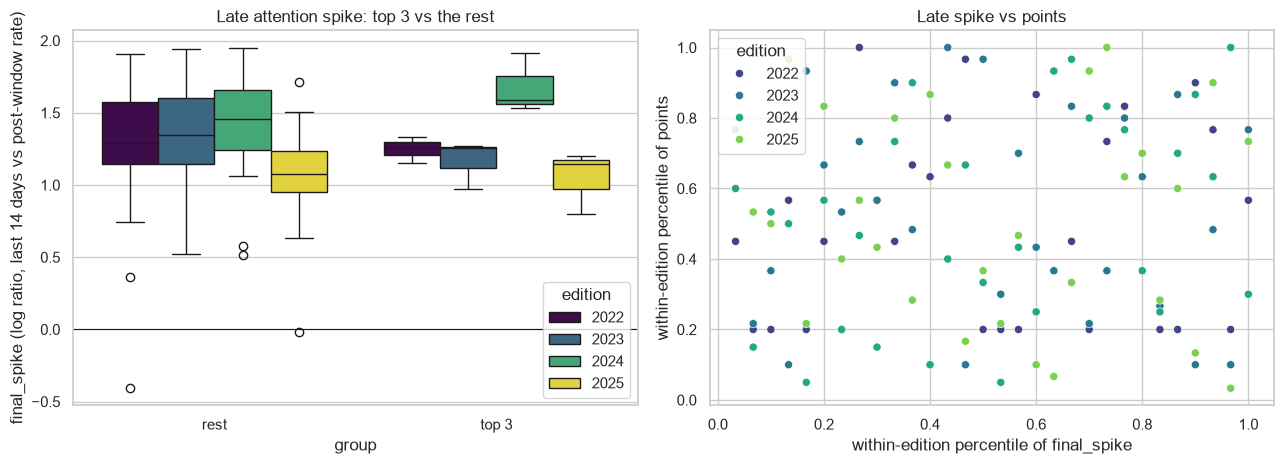

In [40]:
spike_tbl = att_lab[["edition", "player_name", "points", "final_spike"]].copy()
spike_tbl["spike_pctile"] = att_lab_z["final_spike"].groupby(att_lab["edition"]).rank(pct=True)
spike_tbl["points_pctile"] = pooled_att_y
spike_tbl["finish"] = att_lab.groupby("edition")["points"].rank(ascending=False, method="min").astype(int)

top3 = spike_tbl["finish"] <= 3
print("final_spike (log ratio) for the actual top 3 vs the rest, by edition:")
display(spike_tbl.assign(top3=top3).groupby(["edition", "top3"])["final_spike"].agg(["count", "mean", "median"]).unstack().round(3))
u, p = stats.mannwhitneyu(att_lab_z.loc[top3[top3].index, "final_spike"], att_lab_z.loc[top3[~top3].index, "final_spike"])
print(f"Mann-Whitney (z-scored spike, pooled top-3 vs rest): U = {u:.0f}, p = {p:.3f}")

print("\nTop 3 late risers per edition and where they finished:")
display(spike_tbl.sort_values(["edition", "final_spike"], ascending=[True, False]).groupby("edition").head(3)[["edition", "player_name", "final_spike", "finish", "points"]].round(2))
print("Bottom 3 (attention fading into the vote):")
display(spike_tbl.sort_values(["edition", "final_spike"]).groupby("edition").head(3)[["edition", "player_name", "final_spike", "finish", "points"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.boxplot(data=spike_tbl.assign(group=np.where(top3, "top 3", "rest")), x="group", y="final_spike", hue="edition", ax=axes[0], palette="viridis")
axes[0].axhline(0, color="k", linewidth=0.8)
axes[0].set_title("Late attention spike: top 3 vs the rest")
axes[0].set_ylabel("final_spike (log ratio, last 14 days vs post-window rate)")
sns.scatterplot(data=spike_tbl, x="spike_pctile", y="points_pctile", hue=spike_tbl["edition"].astype(str), palette="viridis", ax=axes[1], s=35)
axes[1].set_xlabel("within-edition percentile of final_spike")
axes[1].set_ylabel("within-edition percentile of points")
axes[1].set_title("Late spike vs points")
plt.tight_layout()
plt.savefig("figures/eda/d_final_spike.png", dpi=130)
plt.show()

### D5. Same question for the 2026 forecast pool (features only, no outcome)

In [41]:
att26 = att[att["edition"] == FORECAST_EDITION].copy()
att26["spike_z"] = att_z.loc[att26.index, "final_spike"]
att26["wiki_post_minus_in_z"] = att_z.loc[att26.index, "wiki_post"] - att_z.loc[att26.index, "wiki_in"]
print("2026: players with the strongest late attention spike (final_spike) and the biggest post-window attention gain over in-window:")
display(att26.sort_values("final_spike", ascending=False).head(8)[["player_name", "wiki_in", "wiki_post", "wiki_final14", "final_spike", "spike_z"]].round(2))
display(att26.sort_values("wiki_post_minus_in_z", ascending=False).head(5)[["player_name", "wiki_post_minus_in_z"]].round(2))

2026: players with the strongest late attention spike (final_spike) and the biggest post-window attention gain over in-window:


,player_name,wiki_in,wiki_post,wiki_final14,final_spike,spike_z
147,Willian Pacho,-1.27,-5.78,-3.54,2.24,1.38
149,Harry Kane,1.17,-3.53,-1.42,2.11,1.11
144,Michael Olise,1.24,-3.47,-1.39,2.08,1.05
127,Sadio Mané,0.28,-4.74,-2.79,1.96,0.81
140,Bruno Fernandes,-0.35,-4.47,-2.57,1.90,0.70
138,Marquinhos,-0.45,-4.82,-2.95,1.87,0.63
132,Gabriel Magalhães,-0.96,-5.46,-3.60,1.86,0.61
148,Nuno Mendes,-0.77,-5.53,-3.67,1.86,0.61


,player_name,wiki_post_minus_in_z
126,Rodri,1.71
139,Ferran Torres,1.61
122,Pau Cubarsí,1.29
130,Marc Cucurella,0.85
123,Fabián Ruiz,0.81


## E. How much do performance and attention matter? And is anyone missing out?

**Exploratory and descriptive**, not model selection (the 10-feature models are fitted later under the spec's rules).

**Part 1: variance decomposition.** Candidate inputs are grouped into five blocks: *Performance* (attack rate, ratings, big-stage output), *Trophies and team success*, *Standing* (prior ballot rank, past podiums), *Attention* (Wikipedia and news, before and during the window) and *Position*. For every subset of blocks we fit a ridge regression (fixed alpha = 10, no tuning) of the within-edition points percentile (z-scored) on the blocks, and measure **leave-one-edition-out R²** (out-of-sample, so overfitting does not flatter big blocks). The Shapley value of each block (its average marginal gain over all orderings) splits the total R² fairly even when blocks overlap. Shared variance is split between blocks, so read the shares as *attribution*, not causation.

**Part 2: who misses out?** An on-field model (Performance + Trophies/team + Position, no attention) gives each player an *expected* finish. The player's *attention gap* is their attention minus what their on-field profile predicts. If attention matters, players with a negative gap should finish below expectation.

In [42]:
ALPHA = 10.0
N_BOOT_E = 300

BLOCK_COLS = {
    "Performance": ["club_attack_p90", "intl_attack_p90", "club_avg_rating", "big_game_rating", "ucl_ko_goal_contribs",
                    "tourn_ko_goal_contribs", "final_goal_contribs", "scored_winner_in_final", "tourn_award"],
    "Trophies & team": ["major_titles", "other_honors", "club_rating", "ucl_stage_ord", "nt_stage_ord"],
    "Standing": ["prior_standing", "career_podiums_before"],
    "Position": ["is_defender"],
}
ATTENTION_COLS = ["wiki_pre", "wiki_in", "news_pre", "news_in"]
BLOCK_NAMES = ["Performance", "Trophies & team", "Standing", "Attention", "Position"]

non_att = sum(BLOCK_COLS.values(), [])
Zfull_e = within_edition_z(raw, non_att)
X_blocks = {b: Zfull_e.loc[lab.index, cols].values for b, cols in BLOCK_COLS.items()}
X_blocks["Attention"] = att_lab_z[ATTENTION_COLS].values
editions_e = lab["edition"].values
assert (att_lab.index == lab.index).all()

def within_edition_target(values: pd.Series, eds: np.ndarray) -> np.ndarray:
    s = pd.Series(values.values, index=range(len(values)))
    g = s.groupby(eds)
    return ((s - g.transform("mean")) / g.transform("std", ddof=1)).values

y_pct_e = within_edition_target(lab.groupby("edition")["points"].rank(pct=True), editions_e)
y_log_e = within_edition_target(np.log1p(lab["points"]), editions_e)
print({b: X_blocks[b].shape[1] for b in BLOCK_NAMES})

{'Performance': 9, 'Trophies & team': 5, 'Standing': 2, 'Attention': 4, 'Position': 1}


In [43]:
from math import factorial

def ridge_solve(x_train: np.ndarray, y_train: np.ndarray, alpha: float) -> np.ndarray:
    k = x_train.shape[1]
    return np.linalg.solve(x_train.T @ x_train + alpha * np.eye(k), x_train.T @ y_train)

def loeo_r2(x: np.ndarray, y: np.ndarray, eds: np.ndarray, alpha: float) -> float:
    if x.shape[1] == 0:
        return 0.0
    pred = np.empty_like(y)
    for ed in np.unique(eds):
        te = eds == ed
        pred[te] = x[te] @ ridge_solve(x[~te], y[~te], alpha)
    return 1 - ((y - pred) ** 2).sum() / (y ** 2).sum()

def insample_r2(x: np.ndarray, y: np.ndarray, alpha: float) -> float:
    if x.shape[1] == 0:
        return 0.0
    return 1 - ((y - x @ ridge_solve(x, y, alpha)) ** 2).sum() / (y ** 2).sum()

def all_subset_values(blocks: dict[str, np.ndarray], y: np.ndarray, eds: np.ndarray, alpha: float, scorer: str) -> dict[frozenset, float]:
    values = {}
    for mask in range(2 ** len(BLOCK_NAMES)):
        chosen = frozenset(b for i, b in enumerate(BLOCK_NAMES) if mask >> i & 1)
        x = np.hstack([blocks[b] for b in BLOCK_NAMES if b in chosen]) if chosen else np.empty((len(y), 0))
        values[chosen] = loeo_r2(x, y, eds, alpha) if scorer == "loeo" else insample_r2(x, y, alpha)
    return values

def shapley(values: dict[frozenset, float]) -> pd.Series:
    n = len(BLOCK_NAMES)
    out = {}
    for b in BLOCK_NAMES:
        others = [o for o in BLOCK_NAMES if o != b]
        total = 0.0
        for mask in range(2 ** len(others)):
            s = frozenset(o for i, o in enumerate(others) if mask >> i & 1)
            weight = factorial(len(s)) * factorial(n - len(s) - 1) / factorial(n)
            total += weight * (values[s | {b}] - values[s])
        out[b] = total
    return pd.Series(out)

full = frozenset(BLOCK_NAMES)
res = {}
for label, y_e in (("points percentile", y_pct_e), ("log(1+points)", y_log_e)):
    for scorer in ("loeo", "in-sample"):
        v = all_subset_values(X_blocks, y_e, editions_e, ALPHA, scorer)
        sh = shapley(v)
        res[(label, scorer)] = {"values": v, "shapley": sh, "total": v[full]}
        print(f"{label:18s} {scorer:9s}  total R2 = {v[full]:.3f}   shares: " + ", ".join(f"{b} {sh[b] / sh.sum():.0%}" for b in BLOCK_NAMES))

points percentile  loeo       total R2 = 0.627   shares: Performance 18%, Trophies & team 39%, Standing 6%, Attention 33%, Position 4%
points percentile  in-sample  total R2 = 0.731   shares: Performance 24%, Trophies & team 32%, Standing 11%, Attention 29%, Position 4%
log(1+points)      loeo       total R2 = 0.682   shares: Performance 23%, Trophies & team 35%, Standing 5%, Attention 35%, Position 3%
log(1+points)      in-sample  total R2 = 0.787   shares: Performance 27%, Trophies & team 30%, Standing 11%, Attention 29%, Position 3%


In [44]:
main = res[("points percentile", "loeo")]
v = main["values"]
tbl = pd.DataFrame({
    "alone_R2": [v[frozenset([b])] for b in BLOCK_NAMES],
    "shapley_R2": main["shapley"].values,
    "share_of_explained_%": (main["shapley"] / main["shapley"].sum() * 100).values,
    "unique_R2 (drop-one loss)": [v[full] - v[full - {b}] for b in BLOCK_NAMES],
}, index=BLOCK_NAMES)
display(tbl.round(3))
print(f"Total out-of-sample R2 with all blocks: {main['total']:.3f} (in-sample: {res[('points percentile', 'in-sample')]['total']:.3f})")
print("\nWithout attention vs with attention (LOEO R2):", round(v[full - {"Attention"}], 3), "->", round(v[full], 3))
print("Attention alone:", round(v[frozenset(['Attention'])], 3), "| on-field blocks alone (no attention):", round(v[full - {"Attention", "Standing"}], 3))

,alone_R2,shapley_R2,share_of_explained_%,unique_R2 (drop-one loss)
Performance,0.296,0.114,18.124,-0.019
Trophies & team,0.279,0.243,38.756,0.201
Standing,0.047,0.035,5.552,0.018
Attention,0.295,0.210,33.423,0.160
Position,0.071,0.026,4.145,-0.003


Total out-of-sample R2 with all blocks: 0.627 (in-sample: 0.731)

Without attention vs with attention (LOEO R2): 0.467 -> 0.627
Attention alone: 0.295 | on-field blocks alone (no attention): 0.438


,share_%_p05,share_%_median,share_%_p95
Performance,-4.0,14.8,29.6
Trophies & team,24.3,40.4,66.8
Standing,-15.2,4.8,20.0
Attention,17.9,36.0,55.1
Position,-2.1,3.9,11.8


Out-of-sample total R2, bootstrap 90% interval: [0.432 0.577 0.687]


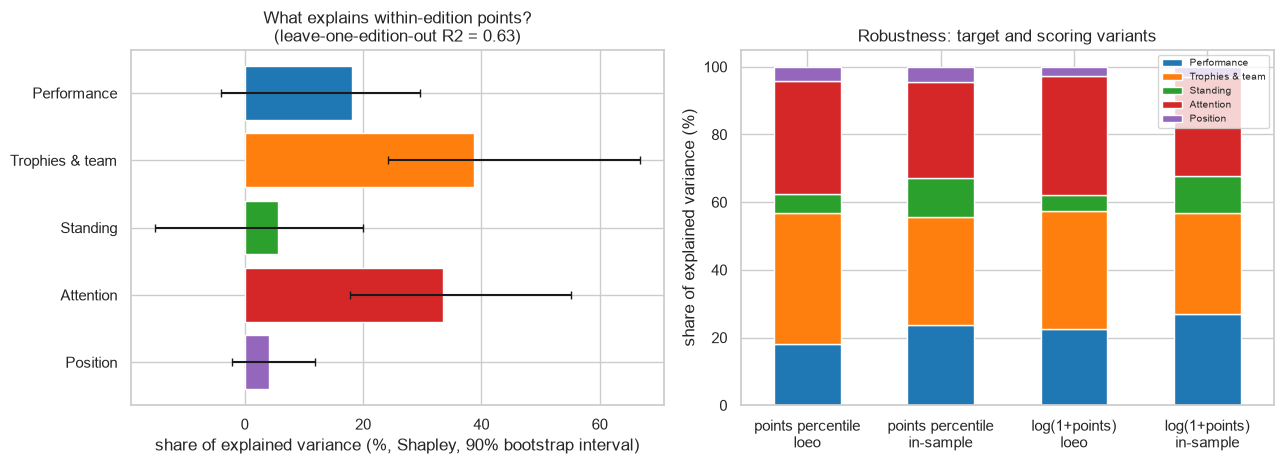

In [45]:
rng_e = np.random.default_rng(SEED)
boot_shares, boot_total = [], []
idx_by_ed = {ed: np.where(editions_e == ed)[0] for ed in np.unique(editions_e)}
for _ in range(N_BOOT_E):
    idx = np.concatenate([rng_e.choice(ix, len(ix), replace=True) for ix in idx_by_ed.values()])
    blocks_b = {b: X_blocks[b][idx] for b in BLOCK_NAMES}
    vb = all_subset_values(blocks_b, y_pct_e[idx], editions_e[idx], ALPHA, "loeo")
    sh = shapley(vb)
    boot_shares.append((sh / sh.sum()).values)
    boot_total.append(vb[full])
boot_shares = pd.DataFrame(boot_shares, columns=BLOCK_NAMES)
ci = boot_shares.quantile([0.05, 0.5, 0.95]).T * 100
ci.columns = ["share_%_p05", "share_%_median", "share_%_p95"]
display(ci.round(1))
print("Out-of-sample total R2, bootstrap 90% interval:", np.percentile(boot_total, [5, 50, 95]).round(3))

# per-edition held-out view of the same fit, and a per-edition share of in-sample variance explained by attention-only
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
share_pt = (main["shapley"] / main["shapley"].sum() * 100)
colors = sns.color_palette("tab10", len(BLOCK_NAMES))
axes[0].barh(BLOCK_NAMES[::-1], share_pt[BLOCK_NAMES[::-1]].values, color=colors[::-1],
             xerr=[(share_pt[BLOCK_NAMES[::-1]] - ci.loc[BLOCK_NAMES[::-1], "share_%_p05"]).values, (ci.loc[BLOCK_NAMES[::-1], "share_%_p95"] - share_pt[BLOCK_NAMES[::-1]]).values], capsize=3)
axes[0].set_xlabel("share of explained variance (%, Shapley, 90% bootstrap interval)")
axes[0].set_title(f"What explains within-edition points?\n(leave-one-edition-out R2 = {main['total']:.2f})")
robust = pd.DataFrame({f"{lab_}\n{sc}": (res[(lab_, sc)]["shapley"] / res[(lab_, sc)]["shapley"].sum() * 100) for lab_, sc in res})
robust.T.plot.bar(stacked=True, ax=axes[1], color=colors, rot=0, legend=True)
axes[1].set_ylabel("share of explained variance (%)")
axes[1].set_title("Robustness: target and scoring variants")
axes[1].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.savefig("figures/eda/e_variance_decomposition.png", dpi=130)
plt.show()

### E2. Is there evidence that better performers with less attention miss out?

In [46]:
def loeo_predictions(x: np.ndarray, y: np.ndarray, eds: np.ndarray, alpha: float) -> np.ndarray:
    pred = np.empty_like(y)
    for ed in np.unique(eds):
        te = eds == ed
        pred[te] = x[te] @ ridge_solve(x[~te], y[~te], alpha)
    return pred

x_onfield = np.hstack([X_blocks["Performance"], X_blocks["Trophies & team"], X_blocks["Position"]])
x_perf = X_blocks["Performance"]
attention_score = X_blocks["Attention"].mean(axis=1)
# attention gap = attention minus what the on-field profile predicts (fit on the other editions only)
gap_onfield = attention_score - loeo_predictions(x_onfield, attention_score, editions_e, ALPHA)
gap_perf = attention_score - loeo_predictions(x_perf, attention_score, editions_e, ALPHA)
resid_onfield = y_pct_e - loeo_predictions(x_onfield, y_pct_e, editions_e, ALPHA)
resid_perf = y_pct_e - loeo_predictions(x_perf, y_pct_e, editions_e, ALPHA)

def boot_spearman(a: np.ndarray, b: np.ndarray, n_boot: int, rng: np.random.Generator) -> tuple[float, float]:
    d = [stats.spearmanr(a[i], b[i])[0] for i in (rng.integers(0, len(a), len(a)) for _ in range(n_boot))]
    return float(np.percentile(d, 5)), float(np.percentile(d, 95))

rows = []
for name, gap, resid in (("on-field model (performance + trophies/team + position)", gap_onfield, resid_onfield),
                         ("performance-only model", gap_perf, resid_perf)):
    rho, p = stats.spearmanr(gap, resid)
    lo, hi = boot_spearman(gap, resid, 2000, rng_e)
    per_ed = [stats.spearmanr(gap[editions_e == ed], resid[editions_e == ed])[0] for ed in (2022, 2023, 2024, 2025)]
    rows.append({"expectation model": name, "rho(attention gap, finish residual)": rho, "p": p, "ci90_lo": lo, "ci90_hi": hi,
                 **{str(ed): v_ for ed, v_ in zip((2022, 2023, 2024, 2025), per_ed)}, "positive editions": int(sum(x > 0 for x in per_ed))})
display(pd.DataFrame(rows).round(3))
print("Positive rho = players with MORE attention than their profile predicts finish ABOVE their expected placing; negative-gap players finish BELOW it.")

,expectation model,"rho(attention gap, finish residual)",p,ci90_lo,ci90_hi,2022,2023,2024,2025,positive editions
0,on-field model (performance + trophies/team + ...,0.541,0.0,0.422,0.641,0.579,0.692,0.673,0.374,4
1,performance-only model,0.445,0.0,0.315,0.563,0.405,0.573,0.594,0.195,4


Positive rho = players with MORE attention than their profile predicts finish ABOVE their expected placing; negative-gap players finish BELOW it.


In [47]:
e2 = pd.DataFrame({
    "edition": editions_e, "player_name": lab["player_name"].values, "points": lab["points"].values,
    "y": y_pct_e, "expected": loeo_predictions(x_onfield, y_pct_e, editions_e, ALPHA),
    "attention": attention_score, "gap": gap_onfield, "resid": resid_onfield,
}, index=lab.index)
e2["expected_rank"] = e2.groupby("edition")["expected"].rank(ascending=False, method="first").astype(int)
e2["finish"] = e2.groupby("edition")["points"].rank(ascending=False, method="min").astype(int)
e2["attention_rank"] = e2.groupby("edition")["attention"].rank(ascending=False, method="first").astype(int)
e2["rank_error"] = e2["finish"] - e2["expected_rank"]          # positive = finished worse than expected
e2["strong"] = e2["expected_rank"] <= 10
e2["low_gap"] = e2["gap"] < 0

print("Players the on-field model expects in the top 10, split by whether their attention is below (gap < 0) or above what that profile predicts:")
summary = e2[e2["strong"]].groupby("low_gap").agg(n=("y", "size"), mean_expected_rank=("expected_rank", "mean"), mean_finish=("finish", "mean"),
                                                   mean_rank_error=("rank_error", "mean"), share_top10_finish=("finish", lambda s: (s <= 10).mean()))
summary.index = summary.index.map({True: "attention below expectation", False: "attention at/above expectation"})
display(summary.round(2))
a = e2[e2["strong"] & e2["low_gap"]]["rank_error"]
b = e2[e2["strong"] & ~e2["low_gap"]]["rank_error"]
u, p = stats.mannwhitneyu(a, b, alternative="greater")
print(f"Mann-Whitney (one-sided: low-attention strong players finished further below expectation): U = {u:.0f}, p = {p:.3f}")

Players the on-field model expects in the top 10, split by whether their attention is below (gap < 0) or above what that profile predicts:


,n,mean_expected_rank,mean_finish,mean_rank_error,share_top10_finish
low_gap,,,,,
attention at/above expectation,16,5.44,4.94,-0.50,0.94
attention below expectation,24,5.54,10.75,5.21,0.54


Mann-Whitney (one-sided: low-attention strong players finished further below expectation): U = 310, p = 0.001


In [48]:
snubbed = e2[(e2["expected_rank"] <= 8) & (e2["rank_error"] >= 6)].sort_values("rank_error", ascending=False)
snubbed = snubbed.assign(attention_pctile=e2.groupby("edition")["attention"].rank(pct=True).loc[snubbed.index])
print("'Snubbed' candidates: expected top 8 on the field model but finished at least 6 places worse, with their attention:")
display(snubbed[["edition", "player_name", "expected_rank", "finish", "attention_rank", "attention_pctile", "gap"]].round(2))

over = e2[(e2["expected_rank"] >= 12) & (e2["finish"] <= 8)].sort_values("finish")
over = over.assign(attention_pctile=e2.groupby("edition")["attention"].rank(pct=True).loc[over.index])
print("'Overperformers': expected rank 12 or worse but finished top 8, with their attention:")
display(over[["edition", "player_name", "expected_rank", "finish", "attention_rank", "attention_pctile", "gap"]].round(2))

print(f"Snubbed with below-expectation attention: {(snubbed['gap'] < 0).sum()} of {len(snubbed)}; overperformers with above-expectation attention: {(over['gap'] > 0).sum()} of {len(over)}")

'Snubbed' candidates: expected top 8 on the field model but finished at least 6 places worse, with their attention:


,edition,player_name,expected_rank,finish,attention_rank,attention_pctile,gap
112,2025,Michael Olise,8,30,22,0.30,-1.28
97,2025,Fabián Ruiz,5,24,26,0.17,-0.94
10,2022,Christopher Nkunku,8,20,30,0.03,-1.47
90,2025,Désiré Doué,2,14,28,0.10,-1.86
33,2023,İlkay Gündoğan,3,14,21,0.33,-0.59
111,2025,Khvicha Kvaratskhelia,3,12,14,0.57,-0.05
71,2024,Ademola Lookman,8,14,24,0.23,-1.40


'Overperformers': expected rank 12 or worse but finished top 8, with their attention:


,edition,player_name,expected_rank,finish,attention_rank,attention_pctile,gap
92,2025,Lamine Yamal,14,2,2,0.97,1.49
63,2024,Dani Carvajal,17,4,15,0.53,0.62
94,2025,Mohamed Salah,19,4,6,0.83,1.11
74,2024,Erling Haaland,22,5,3,0.93,1.16
103,2025,Achraf Hakimi,12,6,17,0.47,-0.16
25,2022,Thibaut Courtois,17,7,13,0.60,1.09
42,2023,Victor Osimhen,12,8,19,0.40,-0.12
119,2025,Cole Palmer,13,8,10,0.70,0.09


Snubbed with below-expectation attention: 7 of 7; overperformers with above-expectation attention: 6 of 8


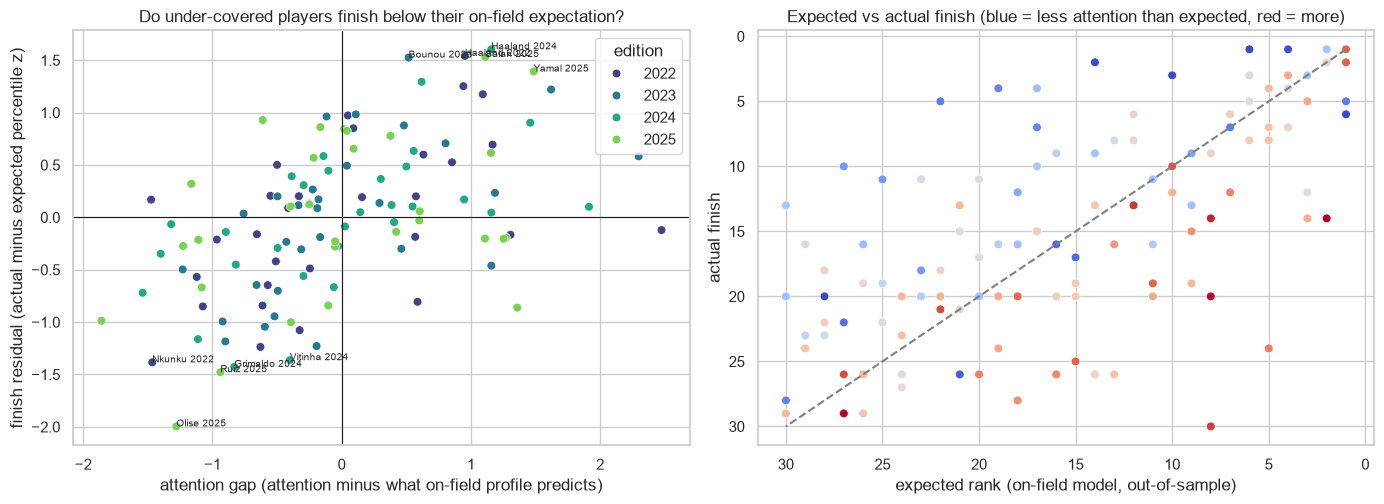

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.scatterplot(data=e2, x="gap", y="resid", hue=e2["edition"].astype(str), palette="viridis", ax=axes[0], s=40)
axes[0].axhline(0, color="k", linewidth=0.8)
axes[0].axvline(0, color="k", linewidth=0.8)
for idx in pd.concat([e2["resid"].nsmallest(5), e2["resid"].nlargest(5)]).index:
    axes[0].annotate(f"{e2.loc[idx, 'player_name'].split()[-1]} {e2.loc[idx, 'edition']}", (e2.loc[idx, "gap"], e2.loc[idx, "resid"]), fontsize=7)
axes[0].set_xlabel("attention gap (attention minus what on-field profile predicts)")
axes[0].set_ylabel("finish residual (actual minus expected percentile z)")
axes[0].set_title("Do under-covered players finish below their on-field expectation?")
sns.scatterplot(data=e2, x="expected_rank", y="finish", hue=e2["gap"].clip(-1.5, 1.5), palette="coolwarm_r", ax=axes[1], s=40, legend=False)
axes[1].plot([1, 30], [1, 30], color="grey", linestyle="--")
axes[1].set_xlabel("expected rank (on-field model, out-of-sample)")
axes[1].set_ylabel("actual finish")
axes[1].invert_xaxis()
axes[1].invert_yaxis()
axes[1].set_title("Expected vs actual finish (blue = less attention than expected, red = more)")
plt.tight_layout()
plt.savefig("figures/eda/e_missing_out.png", dpi=130)
plt.show()